In [1]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.gridspec import GridSpec
from pathlib import Path
import numpy as np
import pandas as pd
import json, hashlib, datetime as dt
import time, pickle, warnings
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score)
import itertools
from sklearn.preprocessing import RobustScaler
from scipy.optimize import linear_sum_assignment
import urllib.request
from matplotlib.patches import Polygon as MplPolygon, Patch

In [89]:
fonts = {
    "RobotoCondensed-Regular.ttf": "https://github.com/googlefonts/roboto/raw/main/src/hinted/RobotoCondensed-Regular.ttf",
    "RobotoCondensed-Bold.ttf": "https://github.com/googlefonts/roboto/raw/main/src/hinted/RobotoCondensed-Bold.ttf"
}

for font_file, font_url in fonts.items():
    if not os.path.exists(font_file):
        urllib.request.urlretrieve(font_url, font_file)
    fm.fontManager.addfont(font_file)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Roboto Condensed', 'Arial', 'sans-serif']
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['figure.titleweight'] = 'bold'

# Step 2: load and audit the data

**Goal**: Get a clean table of countries only, with the supplement merged, estimates and projections flagged, and every missing value explained.

## 2.1 Sets up imports and the data folder, lists the files

**Method**: pathlib with a relative path (../data) instead of a typed Windows path, because a backslash in a normal string (C:\Users) triggers a unicode-escape error

**Output**: The folder path and file sizes

In [3]:
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

DATA_DIR = Path('..') / 'data'
print('Data folder:', DATA_DIR.resolve())
print('Exists:', DATA_DIR.exists())

for p in sorted(DATA_DIR.rglob('*')):
    if p.is_file():
        print(f'{p.stat().st_size / 1e6:9.2f} MB  {p.relative_to(DATA_DIR)}')

Data folder: C:\Users\ACER\OneDrive - Universitas Diponegoro\lomba\asa-dataquest\data
Exists: True
     9.84 MB  processed\aggregates_for_context.csv.gz
     7.13 MB  processed\analysis_countries_1950_2100.csv.gz
     0.03 MB  processed\heldout_2010s_medians.csv
     0.00 MB  processed\missingness_table.csv
     0.01 MB  processed\step5_assignments.csv
     0.00 MB  processed\step5_criteria.csv
     0.09 MB  processed\step5_results.pkl
     0.01 MB  processed\step6_boundary_countries.csv
     0.00 MB  processed\step6b_grid.csv
     0.05 MB  processed\X_all_decade_medians.csv
     0.05 MB  processed\X_primary_decade_medians.csv
    40.82 MB  WPP2024_Demographic_Indicators_Medium_csv\WPP2024_Demographic_Indicators_Medium_csv
    16.56 MB  WPP2024_Demographic_Indicators_Medium_csv.gz
     0.00 MB  WPP2024_Demographic_Indicators_notes.csv
    75.34 MB  WPP2024_Demographic_Indicators_OtherVariants_csv.gz
     2.10 MB  WPP2024_Supplement_Births_and_LE60.csv


## 2.2 Finds and loads the Medium, notes and supplement files

**Method**: Detects gzip by its first two bytes, so it works whether or not the file was already extracted; reads with utf-8-sig to strip the byte-order mark

**Output**: Shapes about 84,360 rows (Medium) and 35,636 rows (supplement)

In [4]:
def find_file(keyword, exclude=()):
    hits = [p for p in DATA_DIR.rglob('*')
            if p.is_file() and keyword in p.name and not any(e in p.name for e in exclude)]
    if not hits:
        raise FileNotFoundError(f'No file containing {keyword!r} in {DATA_DIR.resolve()}')
    print(f'{keyword!r} ->', [str(h.relative_to(DATA_DIR)) for h in hits])
    return hits[0]

def is_gzip(path):
    with open(path, 'rb') as f:
        return f.read(2) == b'\x1f\x8b'

def read_wpp(path):
    comp = 'gzip' if is_gzip(path) else None
    return pd.read_csv(path, compression=comp, encoding='utf-8-sig', low_memory=False)

medium_path = find_file('Demographic_Indicators_Medium_csv', exclude=('OtherVariants',))
notes_path  = find_file('Demographic_Indicators_notes.csv')
supp_path   = find_file('Supplement_Births_and_LE60.csv')

medium = read_wpp(medium_path)
notes  = read_wpp(notes_path)
supp   = read_wpp(supp_path)

print('\nmedium:', medium.shape, '| notes:', notes.shape, '| supp:', supp.shape)
medium.head(3)

'Demographic_Indicators_Medium_csv' -> ['WPP2024_Demographic_Indicators_Medium_csv.gz', 'WPP2024_Demographic_Indicators_Medium_csv\\WPP2024_Demographic_Indicators_Medium_csv']
'Demographic_Indicators_notes.csv' -> ['WPP2024_Demographic_Indicators_notes.csv']
'Supplement_Births_and_LE60.csv' -> ['WPP2024_Supplement_Births_and_LE60.csv']

medium: (84360, 67) | notes: (59, 5) | supp: (35636, 9)


,SortOrder,LocID,Notes,ISO3_code,ISO2_code,SDMX_code,LocTypeID,LocTypeName,ParentID,Location,VarID,Variant,Time,TPopulation1Jan,TPopulation1July,TPopulationMale1July,TPopulationFemale1July,PopDensity,PopSexRatio,MedianAgePop,NatChange,NatChangeRT,PopChange,PopGrowthRate,DoublingTime,Births,Births1519,CBR,TFR,NRR,MAC,SRB,Deaths,DeathsMale,DeathsFemale,CDR,LEx,LExMale,LExFemale,LE15,LE15Male,LE15Female,LE65,LE65Male,LE65Female,LE80,LE80Male,LE80Female,InfantDeaths,IMR,LBsurvivingAge1,Under5Deaths,Q5,Q0040,Q0040Male,Q0040Female,Q0060,Q0060Male,Q0060Female,Q1550,Q1550Male,Q1550Female,Q1560,Q1560Male,Q1560Female,NetMigrations,CNMR
0,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1950,68501.280,69213.424,35880.164,33333.260,12.5144,107.6407,19.3872,1223.088,17.671,1424.288,2.058,33.6806,2933.594,429.475,42.385,5.9875,1.6659,29.297,105.8,1710.506,896.754,813.752,24.714,38.6085,38.1082,39.1261,44.2999,43.9332,44.7392,10.9511,10.4530,11.4857,4.8798,4.6064,5.1054,600.102,207.0834,2523.217,930.552,326.3591,483.8022,480.5664,488.1621,643.6878,654.5798,631.8067,297.6529,298.4483,297.2079,443.3215,457.3384,427.3167,201.196,2.907
1,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1951,69925.568,70682.760,36615.258,34067.503,12.7800,107.4785,19.4969,1319.315,18.665,1514.384,2.143,32.3447,3012.920,435.748,42.626,5.9815,1.7067,29.309,105.8,1693.605,888.959,804.646,23.961,39.6435,39.1333,40.1776,44.5777,44.1812,45.0496,10.9994,10.4858,11.5551,4.9081,4.6030,5.1636,600.824,200.9781,2603.729,910.110,311.6260,469.2924,465.8440,473.8063,631.3550,642.5944,619.1788,292.4375,293.1236,292.0887,436.9979,451.4368,420.7398,195.070,2.760
2,NaN,5507,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ADB region: Central and West Asia,2,Medium,1952,71439.952,72238.716,37394.815,34843.901,13.0614,107.3210,19.5624,1414.859,19.586,1597.527,2.212,31.3358,3099.971,445.389,42.913,5.9847,1.7433,29.330,105.8,1685.112,884.170,800.942,23.327,40.5673,40.0791,41.0807,44.8853,44.4688,45.3766,11.0501,10.5324,11.6132,4.9267,4.6133,5.1904,602.648,196.0193,2689.275,898.759,299.5189,456.3412,452.3689,461.3362,619.6089,630.8166,607.6061,286.6916,287.3395,286.3341,429.8298,444.5151,413.5565,182.671,2.529


## 2.3 Looks at columns, years, and variants

**Method**: Quick structural check before any filtering

**Output**: Years 1950–2101, one variant (Medium)

In [5]:
print(medium.columns.tolist())
print('\nYears:', medium['Time'].min(), '-', medium['Time'].max())
print('Variants:', medium['Variant'].unique())
print('Locations:', medium['Location'].nunique())

['SortOrder', 'LocID', 'Notes', 'ISO3_code', 'ISO2_code', 'SDMX_code', 'LocTypeID', 'LocTypeName', 'ParentID', 'Location', 'VarID', 'Variant', 'Time', 'TPopulation1Jan', 'TPopulation1July', 'TPopulationMale1July', 'TPopulationFemale1July', 'PopDensity', 'PopSexRatio', 'MedianAgePop', 'NatChange', 'NatChangeRT', 'PopChange', 'PopGrowthRate', 'DoublingTime', 'Births', 'Births1519', 'CBR', 'TFR', 'NRR', 'MAC', 'SRB', 'Deaths', 'DeathsMale', 'DeathsFemale', 'CDR', 'LEx', 'LExMale', 'LExFemale', 'LE15', 'LE15Male', 'LE15Female', 'LE65', 'LE65Male', 'LE65Female', 'LE80', 'LE80Male', 'LE80Female', 'InfantDeaths', 'IMR', 'LBsurvivingAge1', 'Under5Deaths', 'Q5', 'Q0040', 'Q0040Male', 'Q0040Female', 'Q0060', 'Q0060Male', 'Q0060Female', 'Q1550', 'Q1550Male', 'Q1550Female', 'Q1560', 'Q1560Male', 'Q1560Female', 'NetMigrations', 'CNMR']

Years: 1950 - 2101
Variants: <StringArray>
['Medium']
Length: 1, dtype: str
Locations: 553


## 2.4 Separates countries from aggregates

**Method**: Filters on ISO3_code, which is filled only for countries; LocTypeName is blank for many aggregates, so it is not reliable

**Output**: 237 countries and areas (36,024 rows); only the Holy See is missing from the supplement

In [104]:
print(medium.drop_duplicates('Location')['LocTypeName'].value_counts(dropna=False))

# ISO3_code is only filled for real countries
is_country = medium['ISO3_code'].notna()
print('\nRows with ISO3:', is_country.sum(), '| countries:', medium.loc[is_country, 'ISO3_code'].nunique())

# each ISO3 should map to exactly one Location name
print('ISO3 -> Location unique:', (medium[is_country].groupby('ISO3_code')['Location'].nunique() == 1).all())

countries = medium[is_country].copy()
aggregates = medium[~is_country].copy()    # keep for region/income comparisons later

# compare with the supplement coverage
only_medium = set(countries['ISO3_code']) - set(supp['ISO3_code'])
only_supp   = set(supp['ISO3_code']) - set(countries['ISO3_code'])
print('In Medium but not in supplement:', only_medium)   # expected: Holy See
print('In supplement but not in Medium:', only_supp)     # expected: empty

LocTypeName
Country/Area         237
NaN                  234
Ad Hoc groups         23
Subregion             20
SDG region             9
Income group           9
Development group      7
Special other          7
Geographic region      6
World                  1
Name: count, dtype: int64

Rows with ISO3: 36024 | countries: 237
ISO3 -> Location unique: True
In Medium but not in supplement: {'VAT'}
In supplement but not in Medium: set()


## 2.5 Sanity check against the World row

**Method**: Sum of country populations vs the World row for every year

**Output**: Relative difference about 1e-9; 8.092 billion in 2023, so nothing is double-counted

In [7]:
chk = countries.groupby('Time')['TPopulation1July'].sum()
world = (medium[medium['Location'] == 'World']
         .set_index('Time')['TPopulation1July'])

rel_diff = ((chk - world) / world).abs()
print(rel_diff.describe())
print('2023 sum of countries (billions):', round(chk.loc[2023] / 1e6, 3),
      '| World row:', round(world.loc[2023] / 1e6, 3))

count    1.510000e+02
mean     6.336280e-10
std      6.705210e-10
min      0.000000e+00
25%      1.794336e-10
50%      4.182198e-10
75%      9.035137e-10
max      3.609974e-09
Name: TPopulation1July, dtype: float64
2023 sum of countries (billions): 8.092 | World row: 8.092


## 2.6 Merges the supplement and validates it

**Method**: Duplicate-key check, then a left join with validate=one_to_one; births and LE60 consistency checks from the supplement documentation

**Output**: No duplicates; 2101 has no supplement data; births difference within 0.001; LE60 lies between male and female in 100% of rows

In [8]:
# 1. duplicates would multiply rows, so check keys first
print('Duplicate keys, countries:', countries.duplicated(['ISO3_code', 'Time']).sum())
print('Duplicate keys, supp:', supp.duplicated(['ISO3_code', 'Time']).sum())

supp_cols = ['ISO3_code', 'Time', 'BirthsMale', 'BirthsFemale', 'LE60', 'LE60Male', 'LE60Female']
n_before = len(countries)
df = countries.merge(supp[supp_cols], on=['ISO3_code', 'Time'], how='left', validate='one_to_one')
assert len(df) == n_before, 'merge changed the number of rows'

# 2. the supplement covers 1950-2100, Medium goes to 2101
print('\nSupplement missing by year (tail):')
print(df.groupby('Time')['LE60'].apply(lambda s: s.isna().sum()).tail(4))

# 3. consistency checks from the supplement documentation
ok = df.dropna(subset=['LE60'])
print('\nmax |BirthsMale + BirthsFemale - Births|:',
      (ok['BirthsMale'] + ok['BirthsFemale'] - ok['Births']).abs().max())
print('LE60 between male and female (share of rows):',
      (((ok['LE60'] >= ok[['LE60Male', 'LE60Female']].min(axis=1)) &
        (ok['LE60'] <= ok[['LE60Male', 'LE60Female']].max(axis=1)))).mean())

Duplicate keys, countries: 0
Duplicate keys, supp:      0

Supplement missing by year (tail):
Time
2098      1
2099      1
2100      1
2101    237
Name: LE60, dtype: int64

max |BirthsMale + BirthsFemale - Births|: 0.0010000000038417056
LE60 between male and female (share of rows): 1.0


## 2.7 Flags estimates vs projections

**Method**: is_projection = Time at least 2024, so every later figure can mark the boundary

**Output**: Estimates 1950–2023 (74 years); projections 2024–2101

In [9]:
df['is_projection'] = df['Time'] >= 2024
df['period'] = np.where(df['is_projection'], 'Projection (2024+)', 'Estimate (to 2023)')
print(df.groupby('period')['Time'].agg(['min', 'max', 'nunique']))

                     min   max  nunique
period                                 
Estimate (to 2023)  1950  2023       74
Projection (2024+)  2024  2101       78


In [10]:
# identifies small-population countries (decision that needed in Step 5 because tiny populations make rates noisy)
d23 = df[df['Time'] == 2023]
small = d23[d23['TPopulation1July'] < 100][['Location', 'TPopulation1July']]   # under 100,000 people
print(len(small), 'locations under 100k people in 2023')
print(small.sort_values('TPopulation1July').to_string(index=False))

# all country rows should be labelled Country/Area
print('All countries labelled Country/Area:', (countries['LocTypeName'] == 'Country/Area').all())

37 locations under 100k people in 2023
                        Location  TPopulation1July
                        Holy See             0.496
                            Niue             1.817
                         Tokelau             2.398
     Falkland Islands (Malvinas)             3.477
                      Montserrat             4.420
                    Saint Helena             5.288
       Saint Pierre and Miquelon             5.681
                          Tuvalu             9.816
                Saint Barthélemy            11.085
       Wallis and Futuna Islands            11.370
                           Nauru            11.875
                    Cook Islands            14.222
                        Anguilla            14.410
                           Palau            17.727
      Saint Martin (French part)            27.515
Bonaire, Sint Eustatius and Saba            29.898
                      San Marino            33.733
                       Gibraltar           

## 2.8 Missing-value audit

**Method**: Counts missing values per indicator and finds which countries and years carry them

**Output**: See the decision table below

Checked after merging the supplement onto the Medium file (countries only). No values were imputed anywhere.

|  | Where | Count | Cause | Decision | Effect |
| --- | --- | --- | --- | --- | --- |
| 1 | All Medium indicators (TFR, LEx, Births, Deaths, Q5, CNMR, and so on) | 237 per indicator (0.66%) | One row per country, all in the year 2101. The final projection year has no values for these indicators. | Drop the year 2101. Analysis window is 1950-2100. | No missing values remain in these indicators. |
| 2 | Supplement columns: LE60, LE60Male, LE60Female, BirthsMale, BirthsFemale | 388 per column (1.08%) | 237 rows are the year 2101 (supplement ends in 2100) plus 151 rows for the Holy See (VAT, every year 1950-2100). The supplement has no data for it. | Drop 2101 and exclude the Holy See from the analysis. | 236 countries and areas remain. |
| 3 | DoublingTime | 15,863 in the analysis set (44.5%); 16,175 before dropping 2101 and the Holy See | Structural: the value is only reported when population growth is about 0.5% per year or more, so it is missing for shrinking populations and for slow-growing ones (for example Hungary, Czechia, Germany, Bulgaria). Check: 100% of missing rows have PopGrowthRate < 0.5, and the lowest growth with a value is 0.501. About two thirds of the missing rows have zero or negative growth. | Do not impute. Drop the variable from the analysis. | Variable not used. TFR, LEx and LE60 are complete. |
| 4 | Notes (free-text footnotes) | 26,274 | Blank for most rows by design. It is not an indicator. | Drop the column. | None. |
| 5 | ISO2_code | 151 | One country across 151 years. Namibia's code is the text "NA", which pandas reads as missing. | Restore the value "NA". All joins use ISO3_code. | None. |

**Result:** The analysis set (236 countries and areas, 1950-2100) has 0 missing values.

**Reason for not imputing**: The gaps are structural (undefined values, final year, absent country), so any imputed number would be invented data.

In [11]:
indicators = [c for c in df.columns if c in set(notes['Indicator'])]
print('Indicator columns present:', len(indicators))
print('In notes but not in data:', sorted(set(notes['Indicator']) - set(df.columns)))

miss = df[indicators].isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_table = pd.DataFrame({'n_missing': miss, 'pct': (miss / len(df) * 100).round(2)})
print(miss_table)

# which countries/years carry the missing values? (look at the worst indicator)
if len(miss_table):
    worst = miss_table.index[0]
    print(f'\nWorst indicator: {worst}')
    print(df[df[worst].isna()].groupby('Location').size().sort_values(ascending=False).head(10))

Indicator columns present: 59
In notes but not in data: []
                        n_missing    pct
DoublingTime                16175  44.90
LE60Female                    388   1.08
BirthsMale                    388   1.08
LE60                          388   1.08
LE60Male                      388   1.08
BirthsFemale                  388   1.08
TPopulationFemale1July        237   0.66
PopDensity                    237   0.66
PopSexRatio                   237   0.66
TPopulation1July              237   0.66
PopGrowthRate                 237   0.66
Births                        237   0.66
Births1519                    237   0.66
CBR                           237   0.66
TFR                           237   0.66
NRR                           237   0.66
MAC                           237   0.66
SRB                           237   0.66
Deaths                        237   0.66
DeathsMale                    237   0.66
DeathsFemale                  237   0.66
MedianAgePop                  237   0.6

## 2.9 Plausibility checks and units

**Method**: `describe()` on key indicators, units from the notes file, inspection of extreme values

**Output**: Ranges are plausible; extremes match real events (Kuwait 1990–91, Rwanda 1994, Cambodia 1975–79); extremes are kept

In [12]:
key = ['TPopulation1July', 'TFR', 'LEx', 'LE60', 'MedianAgePop', 'CNMR', 'PopGrowthRate', 'IMR']
print(df[key].describe().T[['min', '25%', '50%', '75%', 'max']].round(2))

units = notes.set_index('Indicator')[['IndicatorName', 'Unit']]
print(units.loc[[k for k in key if k in units.index]])

# extreme values
print(df.nlargest(5, 'CNMR')[['Location', 'Time', 'CNMR']])
print(df.nsmallest(5, 'LEx')[['Location', 'Time', 'LEx']])

                     min     25%      50%       75%         max
TPopulation1July    0.50  323.33  4306.69  19368.59  1701283.71
TFR                 0.66    1.62     2.08      3.65        8.86
LEx                10.99   65.53    73.90     81.73       94.67
LE60                3.17   16.66    19.53     24.49       35.18
MedianAgePop       12.62   20.44    31.21     42.37       72.36
CNMR             -709.90   -1.65    -0.22      1.21      357.14
PopGrowthRate     -71.06   -0.15     0.69      1.86       37.89
IMR                 0.10    3.74    11.82     40.26      423.81
                                          IndicatorName                                 Unit
Indicator                                                                                   
TPopulation1July         Total Population, as of 1 July                            thousands
TFR                                Total Fertility Rate                live births per woman
LEx                Life Expectancy at Birth, both se

**Check**: `TFR` roughly between 0.7 and 8, `LEx` between about 20 and 90, and no negative populations. Extreme values (wars, genocide, pandemics, tiny island states) are real events, not errors, so note them but don’t delete them.

## 2.10 Region hierarchy

**Method**: Maps each country to its parent via `LocID` and `ParentID`

**Output**: Subregions found; income groups are not linked to countries in this file

In [13]:
for col in ['LocID', 'ParentID']:
    print(col, col in medium.columns)

if {'LocID', 'ParentID'}.issubset(medium.columns):
    name_by_id = medium.drop_duplicates('LocID').set_index('LocID')['Location']
    parent = (countries.drop_duplicates('ISO3_code')[['ISO3_code', 'Location', 'ParentID']]
              .assign(Parent=lambda d: d['ParentID'].map(name_by_id)))
    print(parent['Parent'].value_counts().head(20))

LocID True
ParentID True
Parent
Caribbean             28
Eastern Africa        20
Western Asia          18
Western Africa        17
Southern Europe       17
Northern Europe       14
South America         14
South-Eastern Asia    11
Eastern Europe        10
Middle Africa          9
Southern Asia          9
Western Europe         9
Polynesia              9
Eastern Asia           8
Central America        8
Northern Africa        7
Micronesia             7
Southern Africa        5
Central Asia           5
Melanesia              5
Name: count, dtype: int64


## 2.11 First save of the dataset

**Method**: Superseded by Cell 2.14

**Output**: Replaced

In [14]:
out_dir = DATA_DIR / 'processed'
out_dir.mkdir(exist_ok=True)

analysis = df[df['Time'] <= 2100].copy()      # supplement ends in 2100
analysis.to_csv(out_dir / 'analysis_countries_1950_2100.csv.gz', index=False, compression='gzip')
aggregates.to_csv(out_dir / 'aggregates_for_context.csv.gz', index=False, compression='gzip')
miss_table.to_csv(out_dir / 'missingness_table.csv')

print('Saved. Analysis shape:', analysis.shape, '| countries:', analysis['ISO3_code'].nunique())

Saved. Analysis shape: (35787, 74) | countries: 237


## 2.12 Checks why `DoublingTime` is missing

**Method**: Tests whether the missing rows have zero or negative growth, and the lowest growth where a value exists

**Output**: Only `DoublingTime` remains missing; the value exists only when growth is at least about 0.5% per year

In [15]:
a = df[(df['Time'] <= 2100) & (df['ISO3_code'] != 'VAT')].copy()

m = a[indicators].isna().sum()
print('Still missing after dropping 2101 and VAT:')
print(m[m > 0])                                   # expect only DoublingTime

dt_missing = a[a['DoublingTime'].isna()]
print('\nDoublingTime missing where growth <= 0:', (dt_missing['PopGrowthRate'] <= 0).mean())
print('Min growth rate where DoublingTime exists:', a.loc[a['DoublingTime'].notna(), 'PopGrowthRate'].min())

Still missing after dropping 2101 and VAT:
DoublingTime    15863
dtype: int64

DoublingTime missing where growth <= 0: 0.6645653407300006
Min growth rate where DoublingTime exists: 0.501


In [16]:
dtm = a[a['DoublingTime'].isna()]
print('Missing rows with PopGrowthRate < 0.5:', (dtm['PopGrowthRate'] < 0.5).mean())
print('Rows with DoublingTime present and growth < 0.5:', int((a['DoublingTime'].notna() & (a['PopGrowthRate'] < 0.5)).sum()))
print('Max growth where DoublingTime is missing:', dtm['PopGrowthRate'].max())

Missing rows with PopGrowthRate < 0.5: 0.9993696022190002
Rows with DoublingTime present and growth < 0.5: 0
Max growth where DoublingTime is missing: 0.5


## 2.13 Builds `country` → `subregion` → `region` and fixes five gaps

**Method**: Joins on `LocID`, never on names; `ParentID` 918 does not exist in the file, so Northern America is assigned manually to BMU, CAN, GRL, SPM and USA; the cell is re-runnable

**Output**: 232 mapped automatically, 5 assigned; six regions in total

In [17]:
for col, asc in [('IMR', False), ('PopGrowthRate', False), ('PopGrowthRate', True), ('CNMR', True)]:
    print(f'\nExtreme {col} ({"lowest" if asc else "highest"}):')
    print(a.sort_values(col, ascending=asc).head(5)[['Location', 'Time', col]].to_string(index=False))

# country -> subregion -> region, joined on LocID (location names are not all unique)
loc = medium.drop_duplicates('LocID').set_index('LocID')[['Location', 'LocTypeName', 'ParentID']]
c = countries.drop_duplicates('ISO3_code')[['ISO3_code', 'ParentID']].copy()
c['Subregion'] = c['ParentID'].map(loc['Location'])
c['Subregion_type'] = c['ParentID'].map(loc['LocTypeName'])
c['Region_id'] = c['ParentID'].map(loc['ParentID'])
c['Region'] = c['Region_id'].map(loc['Location'])
c['Region_type'] = c['Region_id'].map(loc['LocTypeName'])

print('\n', c['Subregion_type'].value_counts(dropna=False))
print('\n', c['Region_type'].value_counts(dropna=False))
print('\n', c.groupby(['Region', 'Subregion']).size())


Extreme IMR (highest):


   Location  Time      IMR
South Sudan  1988 423.8092
      Yemen  1950 343.3954
      Yemen  1951 339.3315
      Yemen  1952 335.3810
      Yemen  1953 331.2165

Extreme PopGrowthRate (highest):
            Location  Time  PopGrowthRate
China, Hong Kong SAR  1964         37.887
    China, Macao SAR  1964         37.095
              Kuwait  1991         36.090
              Rwanda  1996         22.576
               Qatar  2006         22.136

Extreme PopGrowthRate (lowest):
            Location  Time  PopGrowthRate
              Kuwait  1990        -71.064
              Rwanda  1994        -41.785
China, Hong Kong SAR  1967        -33.038
             Liberia  1990        -29.891
         Timor-Leste  1999        -29.083

Extreme CNMR (lowest):
            Location  Time     CNMR
              Kuwait  1990 -709.899
China, Hong Kong SAR  1967 -359.282
             Liberia  1990 -320.437
         Timor-Leste  1999 -315.012
              Rwanda  1994 -305.949

 Subregion_type
Subregion 

### 2.13.b Inspect and fix the 5 missing regions

In [18]:
fix = c['Region'].isna()
tmp = c[fix].copy()
tmp['Country'] = tmp['ISO3_code'].map(
    countries.drop_duplicates('ISO3_code').set_index('ISO3_code')['Location'])
tmp['Parent_name'] = tmp['ParentID'].map(loc['Location'])
tmp['Parent_type'] = tmp['ParentID'].map(loc['LocTypeName'])
print(tmp[['ISO3_code', 'Country', 'ParentID', 'Parent_name', 'Parent_type', 'Subregion']].to_string(index=False))

ISO3_code                   Country  ParentID Parent_name Parent_type Subregion
      BMU                   Bermuda     918.0         NaN         NaN       NaN
      CAN                    Canada     918.0         NaN         NaN       NaN
      GRL                 Greenland     918.0         NaN         NaN       NaN
      SPM Saint Pierre and Miquelon     918.0         NaN         NaN       NaN
      USA  United States of America     918.0         NaN         NaN       NaN


### 2.13.c Verify, then assign

In [19]:
# 1. confirm the evidence
print('918 present as a LocID in the file:', (medium['LocID'] == 918).any())
print(sorted(medium.loc[medium['LocTypeName'] == 'Geographic region', 'Location'].unique()))

# 2. make sure only these five are missing before assigning
na_codes = ['BMU', 'CAN', 'GRL', 'SPM', 'USA']
assert set(c.loc[c['Region'].isna(), 'ISO3_code']) == set(na_codes), 'unexpected missing regions'

# 3. assign (Northern America is both its own subregion and region in the UN scheme)
c.loc[c['ISO3_code'].isin(na_codes), ['Subregion', 'Region']] = 'Northern America'

print('Still missing:', c['Region'].isna().sum())     # expect 0
print(c['Region'].value_counts())

918 present as a LocID in the file: False
['Africa', 'Americas', 'Asia', 'Europe', 'Latin America and the Caribbean', 'Northern America', 'Oceania']
Still missing: 0
Region
Africa                             58
Asia                               51
Europe                             50
Latin America and the Caribbean    50
Oceania                            23
Northern America                    5
Name: count, dtype: int64


## 2.14 Builds the final analysis dataset

**Method**: Drops the Holy See, the year 2101 and `DoublingTime`; adds the `small_pop` flag and the `region` columns; saves a compressed CSV

**Output**: 236 countries and areas, 36 under 100k, primary set 200

In [20]:
d23 = df[df['Time'] == 2023].set_index('ISO3_code')['TPopulation1July']    # thousands
small_codes = d23[d23 < 100].index                                         # under 100,000 people

analysis = df[(df['Time'] <= 2100) & (df['ISO3_code'] != 'VAT')].copy()
analysis['small_pop'] = analysis['ISO3_code'].isin(small_codes)
analysis = analysis.drop(columns=['DoublingTime'])                         # structurally missing
analysis = analysis.merge(c[['ISO3_code', 'Subregion', 'Region']], on='ISO3_code', how='left')

n_all = analysis['ISO3_code'].nunique()
n_small = analysis.loc[analysis['small_pop'], 'ISO3_code'].nunique()
print('Countries and areas:', n_all, '| under 100k:', n_small, '| primary set:', n_all - n_small)
print('Missing region labels:', analysis['Region'].isna().sum())
print('Remaining NaNs in analysis set:', int(analysis.isna().sum().sum()))

out_dir = DATA_DIR / 'processed'
out_dir.mkdir(exist_ok=True)
analysis.to_csv(out_dir / 'analysis_countries_1950_2100.csv.gz', index=False, compression='gzip')

Countries and areas: 236 | under 100k: 36 | primary set: 200
Missing region labels: 0
Remaining NaNs in analysis set: 26425


### 2.14.b Find where the 26,425 are

In [21]:
nn = analysis.isna().sum()
print(nn[nn > 0].sort_values(ascending=False))

ind_in_analysis = [col for col in indicators if col in analysis.columns]
print('\nMissing values in indicator columns only:', int(analysis[ind_in_analysis].isna().sum().sum()))

Notes        26274
ISO2_code      151
dtype: int64

Missing values in indicator columns only: 0


### 2.14.c Finish the clean-up

**Expected**: `NAM` / `Namibia` in the first printout, `Remaining NaNs: 0`, and the shape `(35,636 rows, ...)`, which is 236 countries × 151 years.

In [22]:
# 1. confirm which country has the missing ISO2 code
print(analysis.loc[analysis['ISO2_code'].isna(), ['ISO3_code', 'Location']].drop_duplicates())

# 2. fix only if it is Namibia, drop the free-text notes
isna_iso2 = analysis['ISO2_code'].isna()
if set(analysis.loc[isna_iso2, 'ISO3_code']) <= {'NAM'}:
    analysis.loc[isna_iso2, 'ISO2_code'] = 'NA'
analysis = analysis.drop(columns=['Notes'])

# 3. final checks
print('Remaining NaNs:', int(analysis.isna().sum().sum()))          # target: 0
print('Shape:', analysis.shape, '| countries:', analysis['ISO3_code'].nunique())
print('Years:', analysis['Time'].min(), '-', analysis['Time'].max())

analysis.to_csv(out_dir / 'analysis_countries_1950_2100.csv.gz', index=False, compression='gzip')

     ISO3_code Location
5889       NAM  Namibia
Remaining NaNs: 0
Shape: (35636, 75) | countries: 236
Years: 1950 - 2100


In [23]:
print(sorted(analysis.loc[analysis['Region'] == 'Northern America', 'ISO3_code'].unique()))
print(analysis['Region'].value_counts(dropna=False).div(151).astype(int))   # countries per region

['BMU', 'CAN', 'GRL', 'SPM', 'USA']
Region
Africa                             58
Asia                               51
Latin America and the Caribbean    50
Europe                             49
Oceania                            23
Northern America                    5
Name: count, dtype: int64


# Step 3: lock the plan before modelling

**Goal**: Make every analysis choice before seeing results, so the study cannot be accused of cherry-picking (ASA guideline B3).

## 3.1 Question

How many distinct demographic pathways have countries and areas followed since 1950,
which are converging or diverging, and how robust are those groups to modeling
choices and projection uncertainty?
- Q1 How many pathways exist and who follows each?
- Q2 Are pathways converging or diverging over time?
- Q3 How robust are the groups to methodological choices?
- Q4 Where are they heading, and how uncertain is that?

## 3.2 Data and sample

- UN WPP 2024 Medium variant + supplement (LE60); OtherVariants for projection uncertainty.
- 236 countries and areas, 1950-2100 (estimates to 2023, projections from 2024). Holy See excluded.
- Primary set: 200 countries/areas with >= 100,000 people in 2023. Sensitivity: all 236.

## 3.3 Clustering features (pre-specified)

- Indicators: TFR, LEx (life expectancy at birth), LE60 (life expectancy at 60).
- Primary representation: decade medians for 1950s ... 2010s (7 decades x 3 indicators = 21 features), z-scored.
- 2020-2023 excluded from the primary run (COVID-era mortality shocks).
- HELD OUT (never used to form clusters; used only for validation/description):
  MedianAgePop, CNMR, PopGrowthRate, PopDensity, TPopulation1July, LE60 sex gap (LE60Female - LE60Male).


## 3.4 Methods (pre-specified)

- PCA on the 21 features; keep components explaining >= 90% variance.
- Clustering: k-means, Ward hierarchical, Gaussian mixture; k = 2..10.
- Criteria reported for every k: silhouette, Calinski-Harabasz, Davies-Bouldin, gap statistic, BIC (GMM), bootstrap stability.
- Decision rule for k: choose the k with the highest median bootstrap ARI (500 resamples, 80% subsamples)
  among k whose smallest cluster has >= 5% of countries and whose silhouette is >= 0.25; ties go to the smaller k.
  If no k satisfies this, report that no clear structure was found.
- Validation: ARI and Cramer's V vs the 6 UN geographic regions and 21 subregions; Kruskal-Wallis with
  eta-squared on held-out variables; Holm adjustment for all multiple tests.
- Convergence: cross-country SD of TFR and LEx by decade, and the between-cluster share of variance over time.
- Projections: re-use the fitted pathways to describe 2020-2100 under Medium, and use the 95% PI width of
  population (OtherVariants) for uncertainty.

## 3.5 Hypotheses (a priori)

- H1: Pathways cut across geography: ARI(clusters, UN geographic regions) < 0.5.
- H2: Under Medium, cross-country dispersion of TFR and LEx in 2100 is smaller than in 2019, while the relative
  95% PI width of 2100 population is larger for clusters with higher historical fertility.
- H3: Clusters are moderately robust: median bootstrap ARI >= 0.7, and >= 85% of countries keep the same
  cluster in >= 80% of resamples.

## 3.6 Exploratory aims (declared in advance, reported as exploratory)

- E1: LE60 sex gap by cluster and over time.
- E2: Cluster flows between snapshot years (Sankey), projection years marked.

## 3.7 Sensitivity grid (all reported)

Window (to 2019 / to 2023) x granularity (decade medians / 5-year points) x country set (200 / 236)
x algorithm (3) x scaling (z-score / median-IQR).

## 3.8 Ethical commitments

- Descriptive, neutral cluster names; no rankings and no "better/worse" language.
- "Countries and areas" wording (includes non-sovereign territories).
- Projections shown as scenarios with uncertainty, never as forecasts.
- Values are modeled UN estimates (especially early years and low-data countries); no causal claims;
  national averages hide within-country differences.
- All null or fragile results are reported.

## 3.9 Post hoc rule

Anything added after seeing results is labelled "post hoc / exploratory" in the notebook and on the slides.

In [24]:
PLAN = {
    'locked_on': '2026-10-09',
    'cluster_indicators': ['TFR', 'LEx', 'LE60'],
    'decades_start': [1950, 1960, 1970, 1980, 1990, 2000, 2010],
    'heldout': ['MedianAgePop', 'CNMR', 'PopGrowthRate', 'PopDensity',
                'TPopulation1July', 'LE60Female', 'LE60Male'],
    'primary_set': 'small_pop == False (n=200); sensitivity: all 236',
    'k_range': [2, 10], 'min_cluster_share': 0.05, 'min_silhouette': 0.25,
    'n_bootstrap': 500, 'subsample': 0.8, 'seed': 42,
    'hypotheses': {
        'H1': 'ARI(clusters, UN geographic regions) < 0.5',
        'H2': 'dispersion of TFR/LEx lower in 2100 than 2019 (Medium); relative 95% PI width of 2100 population larger for high-fertility clusters',
        'H3': 'median bootstrap ARI >= 0.7; >= 85% of countries keep cluster in >= 80% of resamples'},
}

plan_text = json.dumps(PLAN, indent=2, sort_keys=True)
plan_path = DATA_DIR.parent / 'analysis_plan.json'
plan_path.write_text(plan_text, encoding='utf-8')
print('Saved', plan_path.resolve())
print('sha256:', hashlib.sha256(plan_text.encode()).hexdigest()[:16], '| locked at', dt.datetime.now().isoformat(timespec='seconds'))

# feasibility checks (no modeling)
needed = PLAN['cluster_indicators'] + PLAN['heldout']
print('All needed columns present:', all(col in analysis.columns for col in needed))

win = analysis[(analysis['Time'] >= 1950) & (analysis['Time'] <= 2019)]
print('Every country has all 70 years in 1950-2019:', win.groupby('ISO3_code').size().eq(70).all())
print('Countries: primary =', analysis.loc[~analysis['small_pop'], 'ISO3_code'].nunique(),
      '| all =', analysis['ISO3_code'].nunique())

# which projection variants does the OtherVariants file contain?
ov_path = find_file('Demographic_Indicators_OtherVariants')
comp = 'gzip' if is_gzip(ov_path) else None
ov_var = pd.read_csv(ov_path, compression=comp, encoding='utf-8-sig', usecols=['Variant'])
print(ov_var['Variant'].value_counts())

Saved C:\Users\ACER\OneDrive - Universitas Diponegoro\lomba\asa-dataquest\analysis_plan.json
sha256: 2db024ebe677bd6a | locked at 2026-10-18T19:15:26
All needed columns present: True
Every country has all 70 years in 1950-2019: True
Countries: primary = 200 | all = 236
'Demographic_Indicators_OtherVariants' -> ['WPP2024_Demographic_Indicators_OtherVariants_csv.gz']
Variant
High                                  43290
Low                                   43290
Constant fertility                    43290
Instant replacement                   43290
Zero migration                        43290
Constant mortality                    43290
No change                             43290
Momentum                              43290
Instant replacement zero migration    43290
No fertility below age 18             43290
Accelerated ABR decline               43290
Accelerated ABR decline with rec      43290
Median PI                             25038
Upper 80 PI                           25038
Lower 80

# Step 4: exploration and feature building

**Goals:**
1. Understand how TFR, LEx and LE60 behave across decades.
2. Check the redundancy among the 21 features.
3. Check skew and outliers.
4. Build the feature matrices exactly as pre-specified.
5. Build the held-out validation table.

**Rules for this step:**
- Everything here is exploratory.
- Don't compute anything about H1 (cluster vs region agreement) yet.
- Don't look at projections yet (H2 concerns 2100).
- Log every decision.

## 4.1 Setup and a decision log

**Method**: Medians are robust to single-year shocks (wars, epidemics)

**Output**: Table of decade medians

In [25]:
OKABE = ['#E69F00', '#56B4E9', '#009E73', '#0072B2', '#D55E00', '#CC79A7', '#000000']   # colorblind-safe
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titleweight': 'bold'})

IND = ['TFR', 'LEx', 'LE60']
DECADES = [1950, 1960, 1970, 1980, 1990, 2000, 2010]
primary_codes = sorted(analysis.loc[~analysis['small_pop'], 'ISO3_code'].unique())
all_codes = sorted(analysis['ISO3_code'].unique())
print(len(primary_codes), len(all_codes))

explog = []
def log(msg):
    explog.append(msg)
    print('LOG:', msg)

# country x decade medians (all 236; filter to primary when needed)
est = analysis[analysis['Time'] <= 2019].copy()
est['decade'] = (est['Time'] // 10) * 10
cd = est.groupby(['ISO3_code', 'decade'])[IND].median().reset_index()

200 236


## 4.2 Distribution of each indicator by decade

**Method**: Quantile tables and histograms, looking for two humps

**Output**: `TFR` median 6.07 → 2.27 and `LEx` 50.5 → 73.1 (1950s → 2010s)


TFR (country decade-medians, primary set)
         min   p10  median   p90   max    sd
decade                                      
1950    1.92  2.59    6.07  7.22  8.22  1.67
1960    1.86  2.53    6.09  7.21  8.26  1.78
1970    1.44  2.05    5.25  7.24  8.35  1.99
1980    1.34  1.78    4.26  6.98  8.81  2.01
1990    1.18  1.49    3.18  6.25  7.80  1.83
2000    0.89  1.35    2.59  5.68  7.77  1.65
2010    0.95  1.46    2.27  4.85  7.28  1.41

LEx (country decade-medians, primary set)
          min    p10  median    p90    max     sd
decade                                           
1950    29.60  36.72   50.54  67.45  73.32  11.50
1960    28.15  40.29   56.91  70.45  73.79  11.28
1970    31.16  43.33   61.51  71.74  74.97  10.66
1980    32.59  47.78   66.19  74.48  77.65  10.15
1990    30.35  49.63   68.79  76.68  79.76   9.96
2000    44.61  53.74   71.42  79.45  82.07   9.33
2010    49.80  59.76   73.07  81.62  84.04   8.10

LE60 (country decade-medians, primary set)
          min  

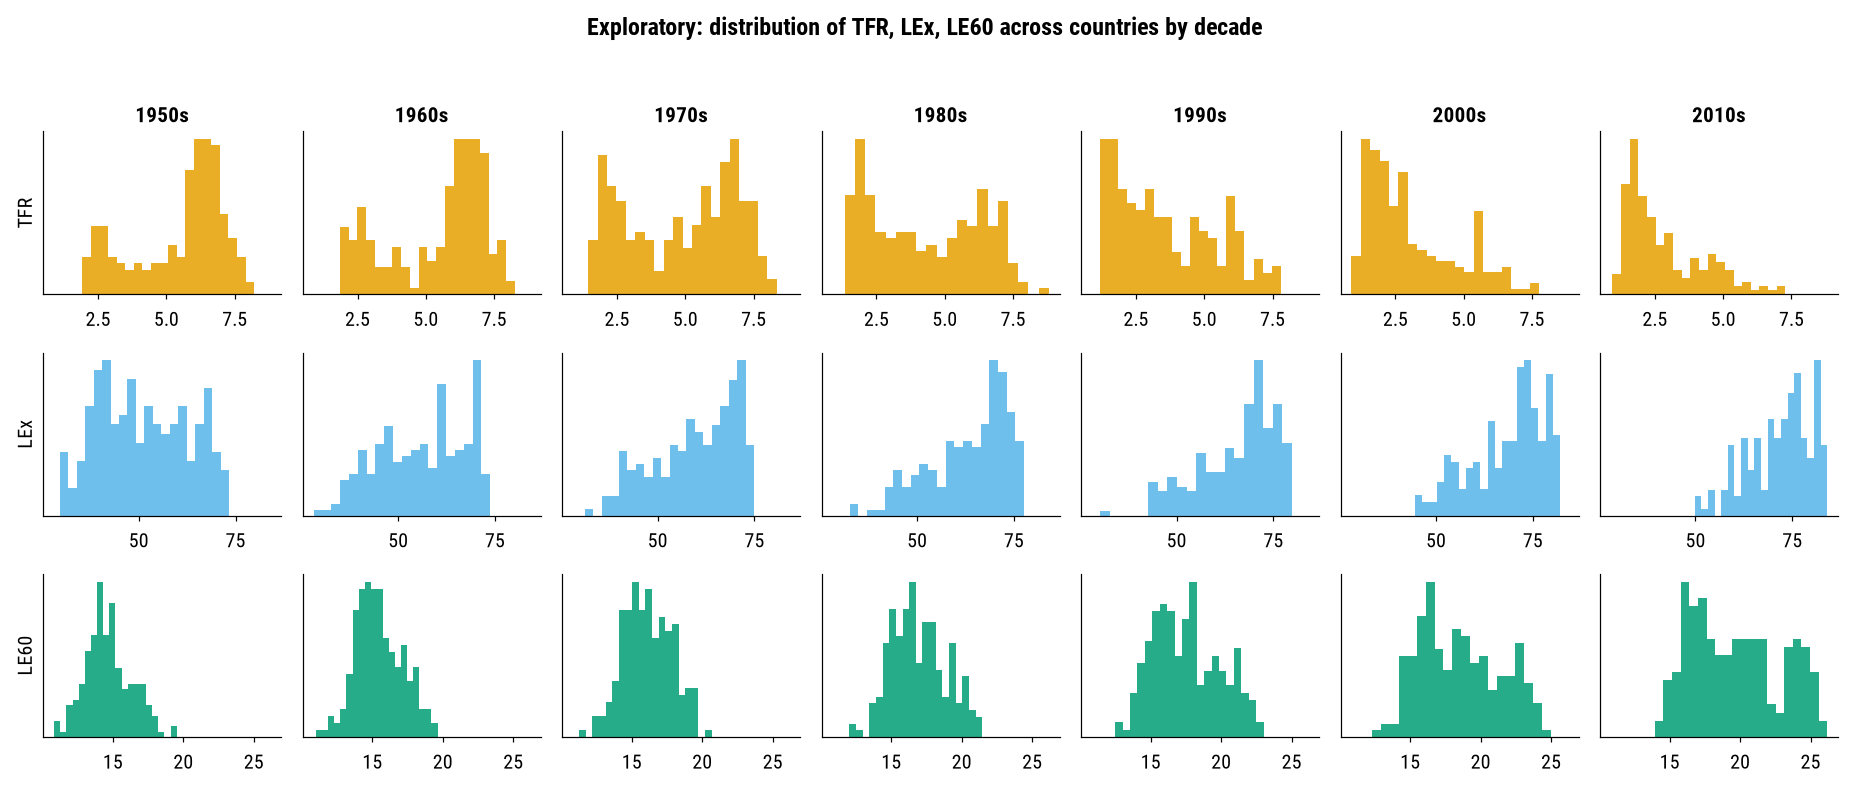

In [101]:
def decade_table(col):
    g = cd[cd['ISO3_code'].isin(primary_codes)].groupby('decade')[col]
    return pd.DataFrame({'min': g.min(), 'p10': g.quantile(.1), 'median': g.median(),
                         'p90': g.quantile(.9), 'max': g.max(), 'sd': g.std()}).round(2)

for col in IND:
    print(f'\n{col} (country decade-medians, primary set)')
    print(decade_table(col))

fig, axes = plt.subplots(3, 7, figsize=(17, 7), sharex='row')
for r, col in enumerate(IND):
    for k, d in enumerate(DECADES):
        v = cd[(cd['decade'] == d) & cd['ISO3_code'].isin(primary_codes)][col]
        axes[r, k].hist(v, bins=20, color=OKABE[r], alpha=.85)
        axes[r, k].set_yticks([])
        if r == 0: axes[r, k].set_title(f'{d}s')
        if k == 0: axes[r, k].set_ylabel(col)
fig.suptitle('Exploratory: distribution of TFR, LEx, LE60 across countries by decade', y=1.02)
plt.tight_layout(); plt.show()

## 4.3 Trajectories 1950–2023

**Method**: Thin lines for all countries, highlighted examples

**Output**: Countries move along a common route; COVID-era dip visible around 2020–21

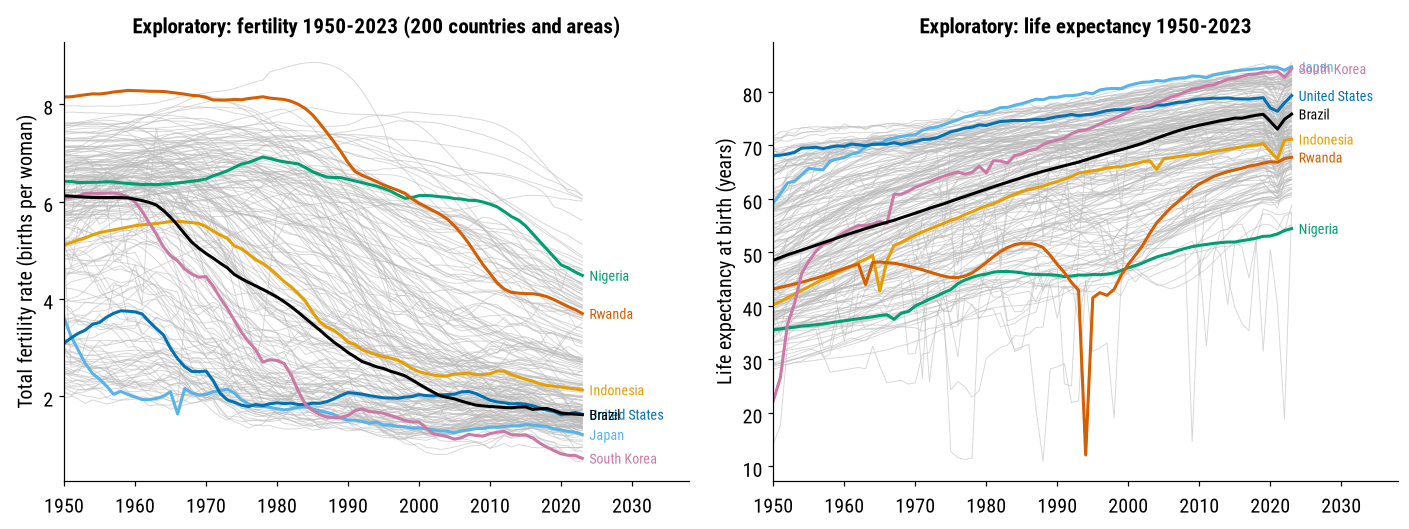

In [102]:
HL = {'IDN': 'Indonesia', 'JPN': 'Japan', 'NGA': 'Nigeria', 'USA': 'United States',
      'RWA': 'Rwanda', 'KOR': 'South Korea', 'BRA': 'Brazil'}
est23 = analysis[(analysis['Time'] <= 2023) & ~analysis['small_pop']].sort_values(['ISO3_code', 'Time'])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, lab in zip(axes, ['TFR', 'LEx'],
                        ['Total fertility rate (births per woman)', 'Life expectancy at birth (years)']):
    for iso, g in est23.groupby('ISO3_code'):
        ax.plot(g['Time'], g[col], color='#BBBBBB', lw=.6, alpha=.6)
    for (iso, name), colr in zip(HL.items(), OKABE):
        g = est23[est23['ISO3_code'] == iso]
        if len(g):
            ax.plot(g['Time'], g[col], color=colr, lw=2)
            ax.text(2024, g[col].iloc[-1], name, color=colr, va='center', fontsize=9)
    ax.set_xlim(1950, 2038); ax.set_ylabel(lab)
axes[0].set_title('Exploratory: fertility 1950-2023 (200 countries and areas)')
axes[1].set_title('Exploratory: life expectancy 1950-2023')
plt.tight_layout(); plt.show()

## 4.4 Paths in the fertility–life expectancy plane

**Method**: Open dot = 1950, filled = 2023

**Output**: One shared corridor, travelled at different times

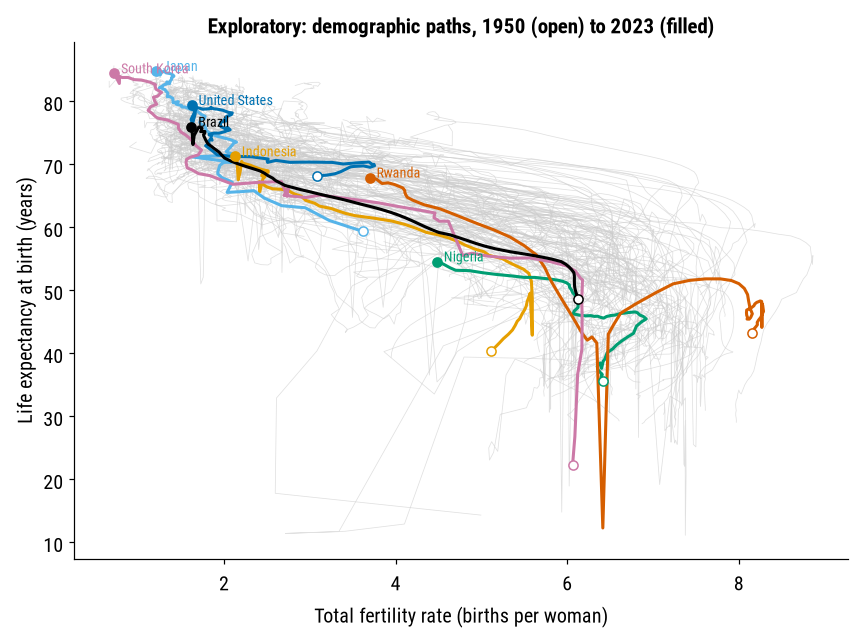

In [103]:
fig, ax = plt.subplots(figsize=(8, 6))
for iso, g in est23.groupby('ISO3_code'):
    ax.plot(g['TFR'], g['LEx'], color='#CCCCCC', lw=.5, alpha=.6)
for (iso, name), colr in zip(HL.items(), OKABE):
    g = est23[est23['ISO3_code'] == iso]
    if len(g):
        ax.plot(g['TFR'], g['LEx'], color=colr, lw=2)
        ax.scatter(g['TFR'].iloc[0], g['LEx'].iloc[0], facecolor='white', edgecolor=colr, zorder=3)   # 1950
        ax.scatter(g['TFR'].iloc[-1], g['LEx'].iloc[-1], color=colr, zorder=3)                         # 2023
        ax.text(g['TFR'].iloc[-1] + .08, g['LEx'].iloc[-1], name, color=colr, fontsize=9)
ax.set_xlabel('Total fertility rate (births per woman)'); ax.set_ylabel('Life expectancy at birth (years)')
ax.set_title('Exploratory: demographic paths, 1950 (open) to 2023 (filled)')
plt.tight_layout(); plt.show()

## 4.5 Correlation of the 21 features

**Method**: Spearman correlation heatmap

**Output**: Same-decade correlations of −0.70 to −0.86 (`TFR`–`LEx`) and 0.81 to 0.97 (`LEx`–`LE60`); justifies PCA

(236, 21) | NaNs: 0


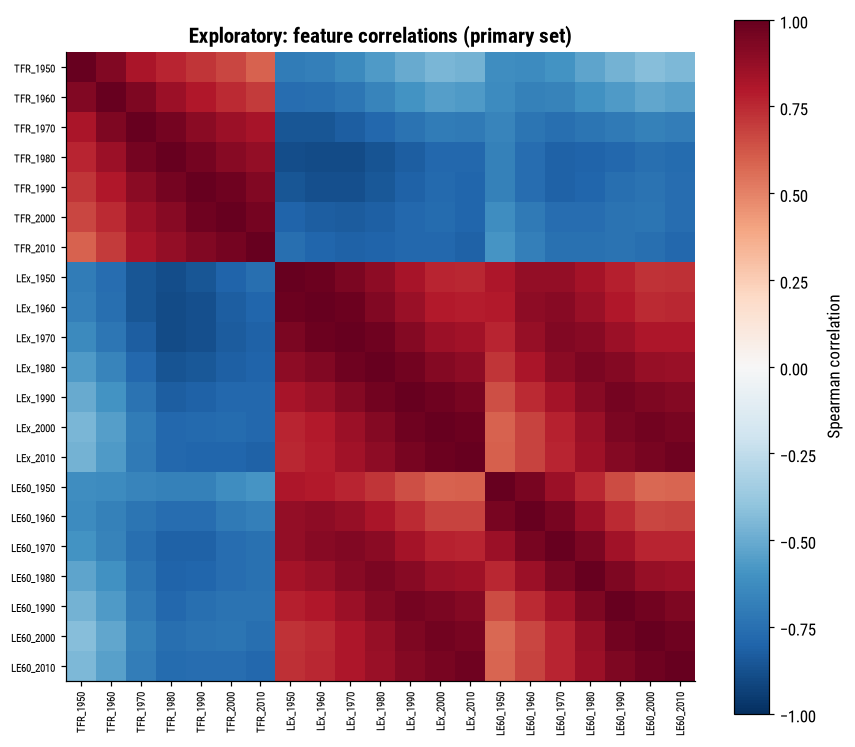

      TFR-LEx  TFR-LE60  LEx-LE60
1950    -0.70     -0.62      0.81
1960    -0.76     -0.68      0.89
1970    -0.83     -0.75      0.93
1980    -0.86     -0.80      0.95
1990    -0.81     -0.76      0.96
2000    -0.77     -0.73      0.96
2010    -0.81     -0.78      0.97


In [88]:
wide = cd.pivot(index='ISO3_code', columns='decade', values=IND)
wide.columns = [f'{i}_{d}' for i, d in wide.columns]
wide = wide[[f'{i}_{d}' for i in IND for d in DECADES]]
print(wide.shape, '| NaNs:', int(wide.isna().sum().sum()))

corr = wide.loc[primary_codes].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(21)); ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticks(range(21)); ax.set_yticklabels(corr.columns, fontsize=7)
plt.colorbar(im, label='Spearman correlation'); ax.set_title('Exploratory: feature correlations (primary set)')
plt.tight_layout(); plt.show()

same_decade = pd.DataFrame({d: {'TFR-LEx': corr.loc[f'TFR_{d}', f'LEx_{d}'],
                                'TFR-LE60': corr.loc[f'TFR_{d}', f'LE60_{d}'],
                                'LEx-LE60': corr.loc[f'LEx_{d}', f'LE60_{d}']} for d in DECADES}).T.round(2)
print(same_decade)

## 4.6 Skewness and outliers

**Method**: Robust z-score using the median absolute deviation, threshold 3.5

**Output**: 7 of 4,200 values flagged; mostly very high fertility (Niger, Somalia, Chad)

In [90]:
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad if mad > 0 else s * 0

Xp = wide.loc[primary_codes]
rz = Xp.apply(robust_z)
diag = pd.DataFrame({'skew': Xp.skew().round(2), 'n_|rz|>3.5': (rz.abs() > 3.5).sum()})
print(diag)

worst = rz.abs().max(axis=1).sort_values(ascending=False).head(8)
print('\nCountries with the most extreme robust z-score on any feature:')
print(worst.round(2))

log('Skew and outliers inspected; outliers kept (real events); primary scaling stays z-score as pre-specified; median-IQR scaling is in the sensitivity grid.')

           skew  n_|rz|>3.5
TFR_1950  -0.76           0
TFR_1960  -0.68           0
TFR_1970  -0.21           0
TFR_1980   0.11           0
TFR_1990   0.50           0
TFR_2000   0.88           0
TFR_2010   1.05           6
LEx_1950   0.12           0
LEx_1960  -0.26           0
LEx_1970  -0.55           0
LEx_1980  -0.78           0
LEx_1990  -0.82           1
LEx_2000  -0.68           0
LEx_2010  -0.57           0
LE60_1950  0.32           0
LE60_1960  0.19           0
LE60_1970  0.07           0
LE60_1980  0.19           0
LE60_1990  0.29           0
LE60_2000  0.26           0
LE60_2010  0.27           0

Countries with the most extreme robust z-score on any feature:
ISO3_code
NER    4.67
SOM    4.43
TCD    4.17
SSD    4.14
COD    3.91
MLI    3.86
CAF    3.57
LVA    3.40
dtype: float64
LOG: Skew and outliers inspected; outliers kept (real events); primary scaling stays z-score as pre-specified; median-IQR scaling is in the sensitivity grid.


### 4.6.b

In [37]:
top = rz.abs().max(axis=1).sort_values(ascending=False).head(8).index
for iso in top:
    f = rz.loc[iso].abs().idxmax()
    print(iso, meta.loc[iso, 'Location'], '|', f, '| robust z =', round(rz.loc[iso, f], 2),
          '| value =', round(Xp.loc[iso, f], 2))

NER Niger | TFR_2010 | robust z = 4.67 | value = 7.28
SOM Somalia | TFR_2010 | robust z = 4.43 | value = 7.02
TCD Chad | TFR_2010 | robust z = 4.17 | value = 6.74
SSD South Sudan | LEx_1990 | robust z = -4.14 | value = 30.35
COD Democratic Republic of the Congo | TFR_2010 | robust z = 3.91 | value = 6.46
MLI Mali | TFR_2010 | robust z = 3.86 | value = 6.41
CAF Central African Republic | TFR_2010 | robust z = 3.57 | value = 6.09
LVA Latvia | TFR_1950 | robust z = -3.4 | value = 1.92


## 4.7 Builds the feature matrices

**Method**: 7 decades × 3 indicators = 21 features; X_primary (200) and X_all (236)

**Output**: `LEx` CV 0.225 → 0.113; `LE60` CV 0.111 → 0.162

In [32]:
X_primary = wide.loc[primary_codes].copy()
X_all = wide.loc[all_codes].copy()
print('X_primary', X_primary.shape, '| X_all', X_all.shape,
      '| NaNs:', int(X_primary.isna().sum().sum() + X_all.isna().sum().sum()))

out_dir = DATA_DIR / 'processed'
X_primary.to_csv(out_dir / 'X_primary_decade_medians.csv')
X_all.to_csv(out_dir / 'X_all_decade_medians.csv')
log('Feature matrices built: decade medians of TFR, LEx, LE60 for 1950s-2010s (21 features); primary n=200, all n=236.')

X_primary (200, 21) | X_all (236, 21) | NaNs: 0
LOG: Feature matrices built: decade medians of TFR, LEx, LE60 for 1950s-2010s (21 features); primary n=200, all n=236.


## 4.8 Held-out table

**Method**: 2010–2019 medians of median age, migration, growth, density, population and the LE60 sex gap; never used to form clusters, so they can validate them

**Output**: 236 × 11 table

In [33]:
h = analysis[(analysis['Time'] >= 2010) & (analysis['Time'] <= 2019)]
held = h.groupby('ISO3_code').agg(MedianAgePop=('MedianAgePop', 'median'),
                                  CNMR=('CNMR', 'median'),
                                  PopGrowthRate=('PopGrowthRate', 'median'),
                                  PopDensity=('PopDensity', 'median'),
                                  Pop_thousands=('TPopulation1July', 'median'))
held['log10_pop'] = np.log10(held['Pop_thousands'] * 1000)
held['LE60_sex_gap'] = (h['LE60Female'] - h['LE60Male']).groupby(h['ISO3_code']).median()

meta = (analysis.drop_duplicates('ISO3_code')
        .set_index('ISO3_code')[['Location', 'Region', 'Subregion', 'small_pop']])
held = held.join(meta)
held.to_csv(out_dir / 'heldout_2010s_medians.csv')
print(held.shape); print(held.describe().T[['min', '50%', 'max']].round(2))
log('Held-out variables summarised as 2010-2019 medians (specified before any clustering).')

(236, 11)
                 min      50%         max
MedianAgePop   14.32    29.12       52.35
CNMR          -39.26    -0.25       44.35
PopGrowthRate  -2.02     1.12        5.40
PopDensity      0.14    92.70    24458.05
Pop_thousands   1.71  5100.16  1392043.07
log10_pop       3.23     6.71        9.14
LE60_sex_gap    0.36     3.13        7.52
LOG: Held-out variables summarised as 2010-2019 medians (specified before any clustering).


## 4.9 Addendum entries

In [34]:
addendum = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'Written after exploratory analysis of distributions, before any clustering or hypothesis test.',
    'clarifications': [
        'Held-out variables are summarised as 2010-2019 medians per country.',
        'Clusters treat every country/area equally (unweighted); population-weighted summaries are reported separately.',
        'Primary scaling remains z-score; median-IQR scaling is a sensitivity run.'],
    'exploration_log': explog,
}
(DATA_DIR.parent / 'analysis_plan_addendum.json').write_text(json.dumps(addendum, indent=2), encoding='utf-8')
print('Addendum saved')

Addendum saved


In [35]:
g = cd[cd['ISO3_code'].isin(primary_codes)].groupby('decade')[IND]
print(pd.concat({'SD': g.std(), 'mean': g.mean(), 'CV': g.std() / g.mean()}, axis=1).round(3))

           SD                  mean                     CV              
          TFR     LEx   LE60    TFR     LEx    LE60    TFR    LEx   LE60
decade                                                                  
1950    1.665  11.498  1.635  5.482  51.193  14.701  0.304  0.225  0.111
1960    1.780  11.284  1.666  5.435  56.036  15.463  0.327  0.201  0.108
1970    1.994  10.660  1.717  4.852  59.830  16.145  0.411  0.178  0.106
1980    2.012  10.147  1.954  4.296  63.357  16.916  0.468  0.160  0.115
1990    1.828   9.958  2.380  3.622  65.680  17.545  0.505  0.152  0.136
2000    1.651   9.329  2.895  3.079  68.642  18.537  0.536  0.136  0.156
2010    1.407   8.102  3.185  2.802  71.783  19.689  0.502  0.113  0.162


## 4.10 Record the addendum

In [36]:
p = DATA_DIR.parent / 'analysis_plan_addendum.json'
add = json.loads(p.read_text(encoding='utf-8')) if p.exists() else {}
add['entry_1'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'Written after exploratory analysis of distributions, before any clustering or hypothesis test.',
    'clarifications': [
        'Held-out variables are 2010-2019 medians per country.',
        'Clusters treat every country/area equally; population-weighted summaries reported separately.',
        'Primary scaling remains z-score; median-IQR scaling is a sensitivity run.',
        'Dispersion over time is reported as SD and CV.'],
}
add['entry_2'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'After viewing exploratory plots, still before any clustering or hypothesis test.',
    'observations': [
        'Countries mostly travel one common TFR-LEx corridor at different times (stage/timing differences).',
        'LEx dispersion falls 1950s->2010s while LE60 dispersion rises (exploratory).',
        'Only 7 of 4200 feature values have |robust z| > 3.5.'],
    'additions': [
        'E3: residual pathways beyond stage (LE60 net of LEx; mortality-fertility transition lag, censoring flagged).',
        'E4: LEx convergence vs LE60 divergence, with caveat on model-based older-age estimates.',
        'If no k passes the pre-specified criteria, report the groups as partitions of a continuum.'],
    'hypotheses_changed': False,
}
add['exploration_log'] = explog
p.write_text(json.dumps(add, indent=2), encoding='utf-8')
print('Addendum saved')

Addendum saved


# 5 PCA, clustering, stability, and the decision rule

## 5.0 Pre-registers the rule clarifications

**Method**: Written and committed before any clustering

**Output**: Addendum entry 3

In [ ]:
p = DATA_DIR.parent / 'analysis_plan_addendum.json'
add = json.loads(p.read_text(encoding='utf-8'))
add['entry_3'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'Written before any clustering was run.',
    'decision_rule_clarifications': [
        'The k-selection rule is applied to every (algorithm, k) pair. Eligible = smallest cluster share >= 5% and silhouette >= 0.25.',
        'Choose the eligible pair with the highest median bootstrap ARI; differences < 0.02 are ties, resolved by smaller k, then order kmeans, ward, gmm.',
        'If no pair is eligible, report that no clear discrete structure was found.',
        'Pre-declared secondary result: same rule restricted to k in 3..8 ("finer partition"), because stability rules favour k=2 for continuous data. Both results are reported.',
        'PCA keeps the smallest number of components explaining >= 90% variance on the full primary set; bootstrap refits scaler and PCA on each 80% subsample.',
        'Small-population countries are assigned out of sample to the nearest cluster centroid.',
        'Cluster labels are letters ordered by PC1 for readability only; they carry no value judgement.'],
}
p.write_text(json.dumps(add, indent=2), encoding='utf-8')
print('Addendum entry_3 saved')

Addendum entry_3 saved


## 5.1 Scalling and PCA

**Method**: z-scores, then PCA keeping at least 90% of variance; the sign of PC1 is fixed on the fitted object

**Output**: 3 components (91.8%); PC1 alone 78.6% is a ‘stage’ axis

Variance explained (first 6): [0.786 0.083 0.049 0.031 0.015 0.01 ]
Cumulative: [0.786 0.869 0.918 0.95  0.965 0.975]
Components kept (>= 90%): 3
            PC1   PC2   PC3
TFR_1950  -0.18  0.42  0.12
TFR_1960  -0.19  0.38  0.17
TFR_1970  -0.22  0.22  0.24
TFR_1980  -0.23  0.10  0.25
TFR_1990  -0.23  0.01  0.31
TFR_2000  -0.22 -0.09  0.36
TFR_2010  -0.21 -0.14  0.36
LEx_1950   0.23 -0.17  0.05
LEx_1960   0.23 -0.10  0.03
LEx_1970   0.23  0.01  0.04
LEx_1980   0.23  0.12  0.04
LEx_1990   0.23  0.23 -0.01
LEx_2000   0.22  0.30 -0.04
LEx_2010   0.22  0.28 -0.04
LE60_1950  0.19 -0.28  0.37
LE60_1960  0.21 -0.23  0.29
LE60_1970  0.22 -0.11  0.30
LE60_1980  0.23  0.04  0.29
LE60_1990  0.22  0.19  0.22
LE60_2000  0.21  0.26  0.16
LE60_2010  0.22  0.25  0.11


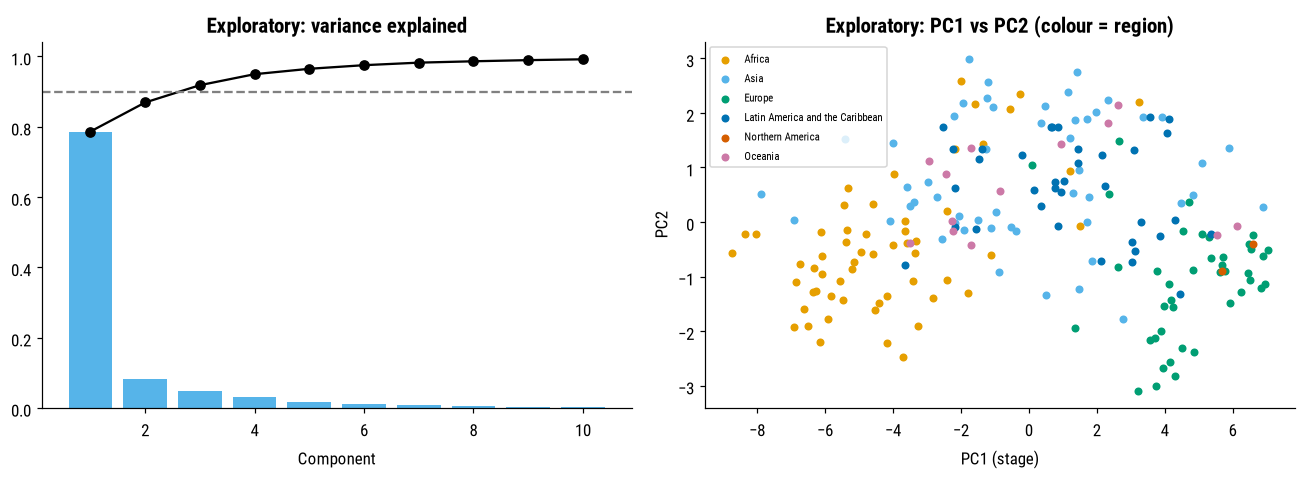

In [91]:
warnings.filterwarnings('ignore', category=ConvergenceWarning)

SEED, K_RANGE, N_BOOT, SUB = 42, list(range(2, 11)), 500, 0.8
ALGOS = ['kmeans', 'ward', 'gmm']

scaler = StandardScaler().fit(X_primary.values)
Z = scaler.transform(X_primary.values)
evr = PCA().fit(Z).explained_variance_ratio_
cum = np.cumsum(evr)
N_COMP = int(np.searchsorted(cum, 0.90) + 1)
print('Variance explained (first 6):', np.round(evr[:6], 3))
print('Cumulative:', np.round(cum[:6], 3))
print('Components kept (>= 90%):', N_COMP)

pca = PCA(n_components=N_COMP).fit(Z)
if pca.components_[0, list(X_primary.columns).index('LEx_2010')] < 0:
    pca.components_[0] *= -1                      # flip the fitted object itself
S = pca.transform(Z)
load = pd.DataFrame(pca.components_.T, index=X_primary.columns,
                    columns=[f'PC{i+1}' for i in range(N_COMP)])
if load.loc['LEx_2010', 'PC1'] < 0:            # orient PC1: higher = longer life expectancy
    load['PC1'] *= -1; S[:, 0] *= -1
print(load.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(range(1, 11), evr[:10], color='#56B4E9'); ax[0].plot(range(1, 11), cum[:10], 'ko-')
ax[0].axhline(.9, ls='--', c='gray'); ax[0].set_xlabel('Component'); ax[0].set_title('Exploratory: variance explained')
regs = meta.loc[X_primary.index, 'Region']
for r, colr in zip(sorted(regs.unique()), OKABE):
    m = (regs == r).values
    ax[1].scatter(S[m, 0], S[m, 1], s=18, color=colr, label=r)
ax[1].set_xlabel('PC1 (stage)'); ax[1].set_ylabel('PC2'); ax[1].legend(fontsize=7)
ax[1].set_title('Exploratory: PC1 vs PC2 (colour = region)')
plt.tight_layout(); plt.show()

## 5.2 Clustering on the full sample

**Method**: k-means, Ward and Gaussian mixture for k = 2–10; silhouette, Calinski–Harabasz, Davies–Bouldin, BIC and the gap statistic

**Output**: A criteria table; the gap statistic suggests k = 5

In [39]:
def fit_labels(Sx, algo, k, seed=SEED, n_init=10):
    if algo == 'kmeans':
        return KMeans(k, n_init=n_init, random_state=seed).fit_predict(Sx)
    if algo == 'ward':
        return AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Sx)
    return GaussianMixture(k, covariance_type='full', n_init=3, reg_covar=1e-4,
                           random_state=seed).fit(Sx).predict(Sx)

rows, base_labels = [], {}
for algo in ALGOS:
    for k in K_RANGE:
        lab = fit_labels(S, algo, k)
        base_labels[(algo, k)] = lab
        sizes = np.bincount(lab, minlength=k)
        ok = len(np.unique(lab)) >= 2
        row = dict(algo=algo, k=k, min_share=sizes.min() / len(lab),
                   silhouette=silhouette_score(S, lab) if ok else np.nan,
                   CH=calinski_harabasz_score(S, lab) if ok else np.nan,
                   DB=davies_bouldin_score(S, lab) if ok else np.nan)
        if algo == 'gmm':
            row['BIC'] = GaussianMixture(k, covariance_type='full', n_init=3, reg_covar=1e-4,
                                         random_state=SEED).fit(S).bic(S)
        rows.append(row)
crit = pd.DataFrame(rows)

def gap_statistic(Sx, ks, B=50, seed=SEED):
    r = np.random.default_rng(seed); lo, hi = Sx.min(0), Sx.max(0); out = []
    for k in ks:
        w = np.log(KMeans(k, n_init=10, random_state=seed).fit(Sx).inertia_)
        wr = np.array([np.log(KMeans(k, n_init=3, random_state=seed)
                              .fit(r.uniform(lo, hi, Sx.shape)).inertia_) for _ in range(B)])
        out.append((k, wr.mean() - w, wr.std() * np.sqrt(1 + 1 / B)))
    return pd.DataFrame(out, columns=['k', 'gap', 's'])

gap = gap_statistic(S, K_RANGE)
tib = next((int(gap.loc[i, 'k']) for i in range(len(gap) - 1)
            if gap.loc[i, 'gap'] >= gap.loc[i + 1, 'gap'] - gap.loc[i + 1, 's']), None)
print('Gap statistic (Tibshirani rule) suggests k =', tib)
print(crit.round(3).to_string(index=False))

Gap statistic (Tibshirani rule) suggests k = 5
  algo  k  min_share  silhouette      CH    DB      BIC
kmeans  2      0.490       0.517 353.070 0.701      NaN
kmeans  3      0.275       0.431 335.651 0.768      NaN
kmeans  4      0.195       0.394 324.385 0.858      NaN
kmeans  5      0.140       0.381 298.805 0.867      NaN
kmeans  6      0.125       0.343 279.014 0.959      NaN
kmeans  7      0.100       0.340 265.043 0.985      NaN
kmeans  8      0.090       0.322 253.289 1.053      NaN
kmeans  9      0.060       0.320 243.665 1.028      NaN
kmeans 10      0.025       0.332 237.881 0.988      NaN
  ward  2      0.280       0.437 203.416 0.698      NaN
  ward  3      0.230       0.408 290.421 0.745      NaN
  ward  4      0.230       0.389 319.199 0.892      NaN
  ward  5      0.085       0.356 277.054 0.911      NaN
  ward  6      0.085       0.310 252.675 0.989      NaN
  ward  7      0.085       0.301 240.617 1.030      NaN
  ward  8      0.085       0.292 230.352 1.040      NaN
 

## 5.3 Bootstrap stability

**Method**: 500 subsamples of 80%; scaler and PCA are refitted inside each resample to avoid leakage; labels matched with the Hungarian algorithm; adjusted Rand index and per-country keep share

**Output**: Median ARI per algorithm and k

In [40]:
def match_to_base(b, lab, k):
    cont = np.zeros((k, k), int); np.add.at(cont, (b, lab), 1)
    r, c = linear_sum_assignment(-cont)
    mp = dict(zip(c, r))
    return np.array([mp.get(l, -1) for l in lab])

Xv = X_primary.values; n = len(Xv); m = int(SUB * n)
rng = np.random.default_rng(SEED)
subsamples = [np.sort(rng.choice(n, m, replace=False)) for _ in range(N_BOOT)]
emb = [PCA(n_components=N_COMP).fit_transform(StandardScaler().fit_transform(Xv[i])) for i in subsamples]

stab_rows, keep = [], {}
t0 = time.time()
for algo in ALGOS:
    for k in K_RANGE:
        base = base_labels[(algo, k)]
        aris, kept, seen = [], np.zeros(n), np.zeros(n)
        for idx, Sb in zip(subsamples, emb):
            lab = fit_labels(Sb, algo, k)
            b = base[idx]
            aris.append(adjusted_rand_score(b, lab))
            kept[idx] += (match_to_base(b, lab, k) == b); seen[idx] += 1
        kp = kept / np.maximum(seen, 1); keep[(algo, k)] = kp
        stab_rows.append(dict(algo=algo, k=k, median_ARI=np.median(aris),
                              ARI_q05=np.quantile(aris, .05), ARI_q95=np.quantile(aris, .95),
                              pct_keep80=(kp >= .8).mean(), mean_keep=kp.mean()))
        print(f'{algo:6s} k={k:2d} median ARI={np.median(aris):.3f}  ({time.time()-t0:.0f}s)')
stab = pd.DataFrame(stab_rows)

kmeans k= 2 median ARI=1.000  (24s)
kmeans k= 3 median ARI=0.979  (38s)
kmeans k= 4 median ARI=0.922  (51s)
kmeans k= 5 median ARI=0.953  (65s)
kmeans k= 6 median ARI=0.787  (78s)
kmeans k= 7 median ARI=0.843  (91s)
kmeans k= 8 median ARI=0.749  (105s)
kmeans k= 9 median ARI=0.737  (121s)
kmeans k=10 median ARI=0.739  (135s)
ward   k= 2 median ARI=0.299  (137s)
ward   k= 3 median ARI=0.479  (139s)
ward   k= 4 median ARI=0.816  (141s)
ward   k= 5 median ARI=0.744  (143s)
ward   k= 6 median ARI=0.699  (145s)
ward   k= 7 median ARI=0.681  (147s)
ward   k= 8 median ARI=0.643  (149s)
ward   k= 9 median ARI=0.643  (151s)
ward   k=10 median ARI=0.648  (153s)
gmm    k= 2 median ARI=0.924  (189s)
gmm    k= 3 median ARI=0.870  (213s)
gmm    k= 4 median ARI=0.514  (247s)
gmm    k= 5 median ARI=0.793  (279s)
gmm    k= 6 median ARI=0.634  (328s)
gmm    k= 7 median ARI=0.618  (378s)
gmm    k= 8 median ARI=0.617  (432s)
gmm    k= 9 median ARI=0.546  (544s)
gmm    k=10 median ARI=0.562  (662s)


## 5.4 Applies the pre-specified rule

**Method**: Eligible if the smallest group is at least 5% and the silhouette is at least 0.25; choose the highest median ARI, ties within 0.02 go to the smaller k

**Output**: Primary: k-means, k = 2 (silhouette 0.517, ARI 1.00). Finer (k 3–8): k-means, k = 3 (0.431, 0.979)


PRIMARY (k 2-10):
{'algo': 'kmeans', 'k': 2.0, 'silhouette': 0.517, 'median_ARI': 1.0, 'pct_keep80': 1.0, 'min_share': 0.49}

FINER (k 3-8, pre-declared):
{'algo': 'kmeans', 'k': 3.0, 'silhouette': 0.431, 'median_ARI': 0.979, 'pct_keep80': 0.975, 'min_share': 0.275}


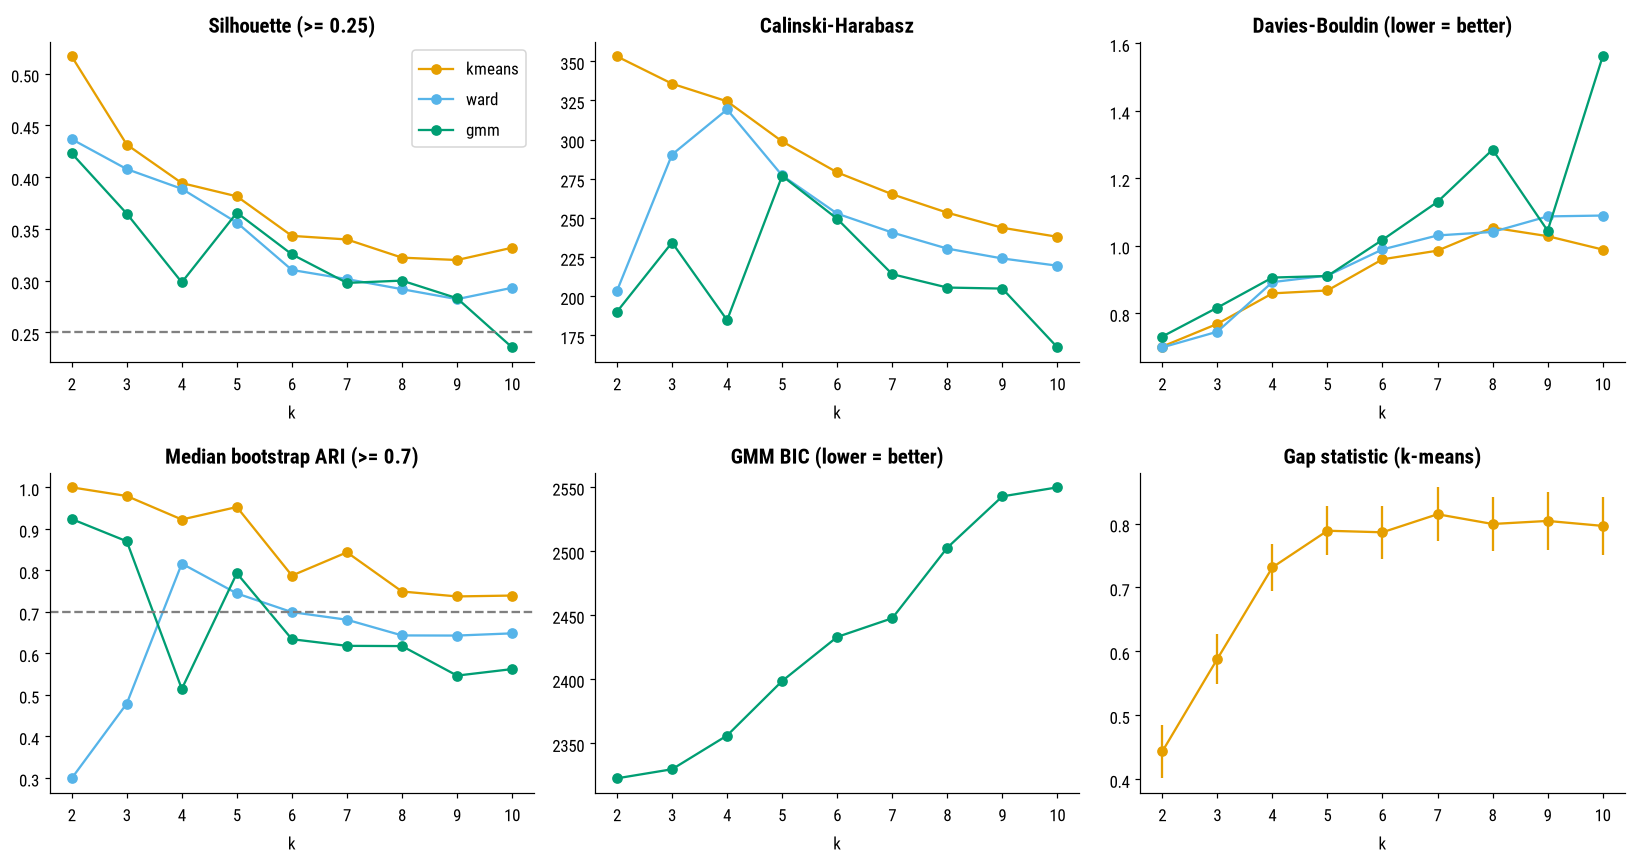

Saved step5_results.pkl


In [92]:
crit = crit.drop(columns=[c for c in stab.columns if c not in ('algo', 'k') and c in crit.columns]).merge(stab, on=['algo', 'k'])
crit['eligible'] = (crit['min_share'] >= 0.05) & (crit['silhouette'] >= 0.25)

def choose(df, kmin, kmax):
    e = df[df['eligible'] & df['k'].between(kmin, kmax)]
    if e.empty: return None
    tied = e[e['median_ARI'] >= e['median_ARI'].max() - 0.02].copy()
    tied['o'] = tied['algo'].map({'kmeans': 0, 'ward': 1, 'gmm': 2})
    return tied.sort_values(['k', 'o']).iloc[0]

primary_choice, finer_choice = choose(crit, 2, 10), choose(crit, 3, 8)
for name, ch in [('PRIMARY (k 2-10)', primary_choice), ('FINER (k 3-8, pre-declared)', finer_choice)]:
    print(f'\n{name}:')
    if ch is None:
        print('No eligible (algorithm, k): report no clear discrete structure.')
    else:
        print({a: (round(float(v), 3) if not isinstance(v, str) else v)
               for a, v in ch[['algo', 'k', 'silhouette', 'median_ARI', 'pct_keep80', 'min_share']].items()})

fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for algo, colr in zip(ALGOS, OKABE):
    d = crit[crit['algo'] == algo]
    axs[0, 0].plot(d['k'], d['silhouette'], 'o-', color=colr, label=algo)
    axs[0, 1].plot(d['k'], d['CH'], 'o-', color=colr)
    axs[0, 2].plot(d['k'], d['DB'], 'o-', color=colr)
    axs[1, 0].plot(d['k'], d['median_ARI'], 'o-', color=colr)
axs[0, 0].axhline(.25, ls='--', c='gray'); axs[1, 0].axhline(.7, ls='--', c='gray')
g = crit[crit['algo'] == 'gmm']; axs[1, 1].plot(g['k'], g['BIC'], 'o-', color=OKABE[2])
axs[1, 2].errorbar(gap['k'], gap['gap'], yerr=gap['s'], fmt='o-', color=OKABE[0])
for a, t in zip(axs.ravel(), ['Silhouette (>= 0.25)', 'Calinski-Harabasz', 'Davies-Bouldin (lower = better)',
                              'Median bootstrap ARI (>= 0.7)', 'GMM BIC (lower = better)', 'Gap statistic (k-means)']):
    a.set_title(t); a.set_xlabel('k')
axs[0, 0].legend(); plt.tight_layout(); plt.show()

out_dir = DATA_DIR / 'processed'
crit.to_csv(out_dir / 'step5_criteria.csv', index=False)
with open(out_dir / 'step5_results.pkl', 'wb') as f:
    pickle.dump(dict(crit=crit, base_labels=base_labels, keep=keep, S=S, N_COMP=N_COMP, load=load,
                     primary=primary_choice, finer=finer_choice, gap=gap), f)
print('Saved step5_results.pkl')

## 5.5 Final labels and small countries

**Method**: Groups are lettered by their PC1 order only (no value judgement); the 36 small areas go to the nearest centroid

**Output**: Group sizes 98/102 (k = 2) and 55/81/64 (k = 3)

In [42]:
from scipy import stats
letters = lambda n: [chr(65 + i) for i in range(n)]

def relabel(lab, Sx):
    k = lab.max() + 1
    cent = np.array([Sx[lab == j].mean(0) for j in range(k)])
    order = np.argsort(cent[:, 0]); remap = {o: i for i, o in enumerate(order)}   # order by PC1: label only, no value judgement
    return np.array([remap[l] for l in lab]), cent[order]

def to_scores(X):
    return pca.transform(scaler.transform(X.values))

SETS = {'primary': (primary_choice['algo'], int(primary_choice['k'])),
        'finer':   (finer_choice['algo'], int(finer_choice['k'])),
        'k5_posthoc': ('kmeans', 5)}

small_codes_ = [c for c in X_all.index if c not in X_primary.index]
assign = pd.DataFrame(index=X_all.index)
LAB = {}
for name, (algo, k) in SETS.items():
    lab, cent = relabel(base_labels[(algo, k)], S)
    Ss = to_scores(X_all.loc[small_codes_])
    ls = ((Ss[:, None, :] - cent[None, :, :]) ** 2).sum(2).argmin(1)      # nearest centroid, out of sample
    col = pd.Series(list(lab) + list(ls), index=list(X_primary.index) + small_codes_)
    assign[name] = col.reindex(assign.index).map(dict(enumerate(letters(k))))
    LAB[name] = pd.Series(lab, index=X_primary.index)
    print(name, algo, k, '| primary sizes', np.bincount(lab), '| small countries', np.bincount(ls, minlength=k))

assign['small_pop'] = ~assign.index.isin(X_primary.index)
assign = assign.join(meta[['Location', 'Region', 'Subregion']])
assign.to_csv(DATA_DIR / 'processed' / 'step5_assignments.csv')
assign.head()

primary kmeans 2 | primary sizes [ 98 102] | small countries [ 7 29]
finer kmeans 3 | primary sizes [55 81 64] | small countries [ 2 15 19]
k5_posthoc kmeans 5 | primary sizes [39 56 43 28 34] | small countries [ 0  7  9  8 12]


,primary,finer,k5_posthoc,small_pop,Location,Region,Subregion
ISO3_code,,,,,,,
ABW,B,C,D,False,Aruba,Latin America and the Caribbean,Caribbean
AFG,A,A,A,False,Afghanistan,Asia,Southern Asia
AGO,A,A,A,False,Angola,Africa,Middle Africa
AIA,B,B,C,True,Anguilla,Latin America and the Caribbean,Caribbean
ALB,B,C,C,False,Albania,Europe,Southern Europe


## 5.6 H1: groups vs UN regions

**Method**: Adjusted Rand index and Cramér’s V with a permutation test

**Output**: ARI 0.23 (k = 2), 0.31 (k = 3); Cramér’s V about 0.67–0.69

In [43]:
rng = np.random.default_rng(SEED)

def cramers_v(a, b):
    t = pd.crosstab(a, b).values; n = t.sum()
    phi2 = stats.chi2_contingency(t, correction=False)[0] / n; r, c = t.shape
    phi2c = max(0, phi2 - (r - 1) * (c - 1) / (n - 1))
    rc, cc = r - (r - 1) ** 2 / (n - 1), c - (c - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / max(1e-12, min(rc - 1, cc - 1)))

def ari_perm(lab, ref, B=2000):
    obs = adjusted_rand_score(lab, ref)
    null = [adjusted_rand_score(lab, rng.permutation(ref)) for _ in range(B)]
    return obs, (1 + sum(x >= obs for x in null)) / (B + 1)

for name, L in LAB.items():
    reg = meta.loc[L.index, 'Region']; sub = meta.loc[L.index, 'Subregion']
    a1, p1 = ari_perm(L.values, reg.values); a2, p2 = ari_perm(L.values, sub.values)
    print(f'\n== {name}: ARI vs 6 regions {a1:.3f} (perm p={p1:.4f}) | vs 21 subregions {a2:.3f} (p={p2:.4f})'
          f' | Cramer V region {cramers_v(L, reg):.3f}, subregion {cramers_v(L, sub):.3f}')
    print(pd.crosstab(reg, L.map(dict(enumerate(letters(L.max() + 1))))))


== primary: ARI vs 6 regions 0.225 (perm p=0.0005) | vs 21 subregions 0.059 (p=0.0005) | Cramer V region 0.685, subregion 0.703
col_0                             A   B
Region                                 
Africa                           54   3
Asia                             27  24
Europe                            0  41
Latin America and the Caribbean   9  27
Northern America                  0   2
Oceania                           8   5

== finer: ARI vs 6 regions 0.311 (perm p=0.0005) | vs 21 subregions 0.101 (p=0.0005) | Cramer V region 0.669, subregion 0.695
col_0                             A   B   C
Region                                     
Africa                           45  11   1
Asia                              8  35   8
Europe                            0   3  38
Latin America and the Caribbean   1  22  13
Northern America                  0   0   2
Oceania                           1  10   2

== k5_posthoc: ARI vs 6 regions 0.244 (perm p=0.0005) | vs 21 subregion

## 5.7 Held-out validation

**Method**: Kruskal–Wallis with epsilon-squared and Holm correction

**Output**: Median age (ε² 0.69–0.78) and population growth differ strongly; population size does not

In [44]:
def holm(p):
    p = np.asarray(p); m = len(p); adj = np.empty(m); run = 0
    for rank, i in enumerate(np.argsort(p)):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1, run)
    return adj

HV = ['MedianAgePop', 'CNMR', 'PopGrowthRate', 'PopDensity', 'log10_pop', 'LE60_sex_gap']
for name, L in LAB.items():
    hh = held.loc[L.index].assign(c=L.values)
    rows = []
    for v in HV:
        H, p = stats.kruskal(*[g[v].values for _, g in hh.groupby('c')])
        rows.append((v, H, p, H / (len(hh) - 1)))                 # epsilon-squared
    kw = pd.DataFrame(rows, columns=['var', 'H', 'p', 'eps2']); kw['p_holm'] = holm(kw['p'])
    print(f'\n== {name}'); print(kw.round(4).to_string(index=False))
    med = hh.groupby('c')[['MedianAgePop', 'CNMR', 'PopGrowthRate', 'LE60_sex_gap']].median().round(2)
    med.index = letters(L.max() + 1); print(med)


== primary
          var        H      p   eps2  p_holm
 MedianAgePop 137.9515 0.0000 0.6932  0.0000
         CNMR   8.3162 0.0039 0.0418  0.0079
PopGrowthRate  75.0148 0.0000 0.3770  0.0000
   PopDensity  13.2953 0.0003 0.0668  0.0008
    log10_pop   3.3060 0.0690 0.0166  0.0690
 LE60_sex_gap  80.7068 0.0000 0.4056  0.0000
   MedianAgePop  CNMR  PopGrowthRate  LE60_sex_gap
A         19.95 -0.69           2.24          2.03
B         36.14  0.43           0.51          3.79

== finer
          var        H      p   eps2  p_holm
 MedianAgePop 156.0914 0.0000 0.7844  0.0000
         CNMR  13.3081 0.0013 0.0669  0.0039
PopGrowthRate  86.7853 0.0000 0.4361  0.0000
   PopDensity  10.2429 0.0060 0.0515  0.0119
    log10_pop   3.4542 0.1778 0.0174  0.1778
 LE60_sex_gap  96.3162 0.0000 0.4840  0.0000
   MedianAgePop  CNMR  PopGrowthRate  LE60_sex_gap
A         17.51 -0.48           2.62          1.73
B         26.42 -0.82           1.22          3.13
C         39.21  1.23           0.28      

## 5.8 Null check (post hoc)

**Method**: 500 Gaussian datasets with the same covariance; compare silhouettes

**Output**: Observed silhouette exceeds the null 95th percentile for k = 2–5, but modestly: moderate structure on a strong continuum

In [45]:
C = np.cov(S.T); mu = S.mean(0); Bn = 500; rows = []
for k in [2, 3, 4, 5]:
    obs = silhouette_score(S, KMeans(k, n_init=10, random_state=SEED).fit_predict(S))
    sims = []
    for b in range(Bn):
        Sim = rng.multivariate_normal(mu, C, size=len(S))
        sims.append(silhouette_score(Sim, KMeans(k, n_init=3, random_state=b).fit_predict(Sim)))
    sims = np.array(sims)
    rows.append((k, obs, sims.mean(), np.quantile(sims, .95), (1 + (sims >= obs).sum()) / (Bn + 1)))
print(pd.DataFrame(rows, columns=['k', 'observed', 'null_mean', 'null_p95', 'p']).round(3))
print('PC1 skew/kurtosis:', round(stats.skew(S[:, 0]), 3), round(stats.kurtosis(S[:, 0]), 3))

   k  observed  null_mean  null_p95      p
0  2     0.517      0.442     0.474  0.002
1  3     0.431      0.374     0.407  0.006
2  4     0.394      0.329     0.358  0.002
3  5     0.381      0.296     0.327  0.002
PC1 skew/kurtosis: -0.078 -1.054


## 5.9 Addendum entry 4

**Method**: Records what is post hoc

**Output**: k = 5 view, null test, D-vs-E description

In [46]:
p = DATA_DIR.parent / 'analysis_plan_addendum.json'
add = json.loads(p.read_text(encoding='utf-8'))
add['entry_4'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'Written after seeing the k-selection results. The rule itself was locked earlier and applied unchanged.',
    'locked_rule_result': {'primary': 'kmeans k=2', 'finer': 'kmeans k=3'},
    'post_hoc': ['k=5 view (gap statistic suggestion)',
                 'Gaussian-null silhouette test for structure vs continuum',
                 'Description of D vs E difference at k=5 (exploratory)'],
}
p.write_text(json.dumps(add, indent=2), encoding='utf-8'); print('entry_4 saved')

entry_4 saved


## 5.10 Group membership

**Method**: Lists countries by group at k = 5

**Output**: D: mostly Eastern Europe plus some Caribbean and others; E: mostly Western, Northern and Southern Europe, East Asia, North America

In [47]:
L3 = assign.loc[X_primary.index, 'finer']
L5 = assign.loc[X_primary.index, 'k5_posthoc']
names = meta['Location']

for g in ['A', 'B', 'C']:
    ix = L5[L5 == g].index
    print(f'Group {g} (k=5): {len(ix)} | top subregions:', meta.loc[ix, 'Subregion'].value_counts().head(6).to_dict())

for g in ['D', 'E']:
    ix = L5[L5 == g].index
    print(f'\nGroup {g} (k=5): {len(ix)} countries and areas')
    print('  subregions:', meta.loc[ix, 'Subregion'].value_counts().to_dict())
    print('  ', ', '.join(names[ix]))

Group A (k=5): 39 | top subregions: {'Eastern Africa': 14, 'Western Africa': 14, 'Middle Africa': 6, 'Southern Africa': 2, 'Southern Asia': 1, 'South-Eastern Asia': 1}
Group B (k=5): 56 | top subregions: {'Western Asia': 7, 'Southern Asia': 7, 'Northern Africa': 6, 'South-Eastern Asia': 5, 'Melanesia': 4, 'Central America': 4}
Group C (k=5): 43 | top subregions: {'South America': 8, 'Western Asia': 6, 'Caribbean': 6, 'South-Eastern Asia': 5, 'Eastern Africa': 4, 'Southern Europe': 3}

Group D (k=5): 28 countries and areas
  subregions: {'Eastern Europe': 10, 'Caribbean': 5, 'Southern Europe': 5, 'Northern Europe': 3, 'Western Asia': 2, 'South America': 1, 'Central Asia': 1, 'Eastern Asia': 1}
   Aruba, Argentina, Armenia, Bulgaria, Bahamas, Belarus, Barbados, Curaçao, Czechia, Estonia, Georgia, Croatia, Hungary, Jamaica, Kazakhstan, Lithuania, Latvia, Republic of Moldova, North Macedonia, Montenegro, Poland, Dem. People's Republic of Korea, Romania, Russian Federation, Serbia, Slovakia

## 5.11 E3a: LE60 net of LEx

**Method**: Quadratic fit of LE60 on LEx per decade, then group comparisons of the residual

**Output**: $R^2$ rises from 0.69 to 0.95; leftover effects are small (SD 0.73 years)

In [48]:
resid = {}
for d in [1950, 1980, 2010]:
    t = cd[(cd['decade'] == d) & cd['ISO3_code'].isin(X_primary.index)].set_index('ISO3_code')
    co = np.polyfit(t['LEx'], t['LE60'], 2)
    resid[d] = t['LE60'] - np.polyval(co, t['LEx'])
    r2 = 1 - resid[d].var() / t['LE60'].var()
    print(f'{d}s: LE60 ~ quadratic(LEx): R2 = {r2:.3f}, residual SD = {resid[d].std():.2f} years')

r = resid[2010]
dfr = pd.DataFrame({'resid': r, 'k3': L3, 'k5': L5, 'Region': meta.loc[r.index, 'Region']})
print(dfr.groupby('k5')['resid'].agg(['median', 'mean', 'std']).round(2))
print(dfr.groupby('Region')['resid'].median().round(2))
for col in ['k3', 'k5', 'Region']:
    H, p = stats.kruskal(*[g['resid'].values for _, g in dfr.groupby(col)])
    print(f'Kruskal-Wallis, residual by {col}: H={H:.1f}, p={p:.4f}, eps2={H/(len(dfr)-1):.3f}')

1950s: LE60 ~ quadratic(LEx): R2 = 0.693, residual SD = 0.91 years
1980s: LE60 ~ quadratic(LEx): R2 = 0.862, residual SD = 0.73 years
2010s: LE60 ~ quadratic(LEx): R2 = 0.947, residual SD = 0.73 years
    median  mean   std
k5                    
A     0.13  0.14  0.71
B    -0.20 -0.19  0.78
C    -0.09  0.20  0.86
D    -0.48 -0.30  0.61
E     0.06  0.14  0.40
Region
Africa                             0.14
Asia                              -0.25
Europe                            -0.16
Latin America and the Caribbean    0.56
Northern America                   0.64
Oceania                           -0.50
Name: resid, dtype: float64
Kruskal-Wallis, residual by k3: H=6.6, p=0.0367, eps2=0.033
Kruskal-Wallis, residual by k5: H=15.5, p=0.0038, eps2=0.078
Kruskal-Wallis, residual by Region: H=27.4, p=0.0000, eps2=0.137


## 5.12 E3b: transition lag

**Method**: Five-year rolling medians; thresholds LEx 60 and TFR 3; censoring reported, not imputed

**Output**: 97 of 200 observed; mortality first in 96; median lag 19 years; 55 countries not yet below TFR 3

In [49]:
e23 = analysis[(analysis['Time'] <= 2023) & analysis['ISO3_code'].isin(X_primary.index)].sort_values(['ISO3_code', 'Time'])
rows = []
for iso, g in e23.groupby('ISO3_code'):
    g = g.set_index('Time')
    lex = g['LEx'].rolling(5, center=True, min_periods=3).median()
    tfr = g['TFR'].rolling(5, center=True, min_periods=3).median()
    rows.append(dict(iso=iso, t_m=lex[lex >= 60].index.min(), t_f=tfr[tfr < 3].index.min()))
lag = pd.DataFrame(rows).set_index('iso')
lag['m_left'] = lag['t_m'] <= 1951; lag['f_left'] = lag['t_f'] <= 1951
lag['m_never'] = lag['t_m'].isna(); lag['f_never'] = lag['t_f'].isna()

print('Mortality threshold: already crossed at start', int(lag['m_left'].sum()), '| never', int(lag['m_never'].sum()))
print('Fertility threshold: already crossed at start', int(lag['f_left'].sum()), '| not yet by 2023', int(lag['f_never'].sum()))

ok = lag[~lag[['m_left', 'f_left', 'm_never', 'f_never']].any(axis=1)].copy()
ok['lag'] = ok['t_f'] - ok['t_m']
ok['k5'] = L5; ok['Region'] = meta.loc[ok.index, 'Region']
print('Uncensored on both:', len(ok)); print(ok['lag'].describe().round(1))
print(ok.groupby('k5')['lag'].agg(['count', 'median', 'min', 'max']).round(1))
print(ok.groupby('Region')['lag'].agg(['count', 'median']).round(1))
print('Mortality first:', int((ok['lag'] > 0).sum()), '| fertility first:', int((ok['lag'] < 0).sum()))
print('Fertility transition not yet reached:', ', '.join(names[lag[lag['f_never']].index]))

Mortality threshold: already crossed at start 41 | never 6
Fertility threshold: already crossed at start 29 | not yet by 2023 55
Uncensored on both: 97
count    97.0
mean     21.4
std      11.6
min      -2.0
25%      12.0
50%      19.0
75%      30.0
max      51.0
Name: lag, dtype: float64
    count  median   min   max
k5                           
A       2    26.0  18.0  34.0
B      39    15.0  -2.0  51.0
C      39    24.0   3.0  45.0
D      10    15.0   1.0  33.0
E       7    19.0  14.0  38.0
                                 count  median
Region                                        
Africa                              14    17.5
Asia                                40    18.0
Europe                               8    12.0
Latin America and the Caribbean     31    24.0
Oceania                              4    34.5
Mortality first: 96 | fertility first: 1
Fertility transition not yet reached: Afghanistan, Angola, Burundi, Benin, Burkina Faso, Central African Republic, Côte d'Ivoire, 

## 5.13 E1: sex gap in LE60

**Method**: Median female-minus-male gap by group and decade

**Output**: Gap diverges between groups D (4.58 years) and E (3.55)

k3         A     B     C
decade                  
1950    0.90  1.52  2.38
1960    1.09  1.72  3.08
1970    1.21  2.01  3.72
1980    1.37  2.43  4.15
1990    1.34  2.76  4.16
2000    1.32  2.93  3.95
2010    1.71  3.15  4.01
k5         A     B     C     D     E
decade                              
1950    0.85  1.28  1.73  2.24  2.40
1960    1.02  1.40  1.88  2.81  3.13
1970    1.12  1.68  2.36  3.36  3.78
1980    1.29  2.01  2.82  3.94  4.20
1990    1.24  2.17  3.10  4.08  4.16
2000    1.14  2.30  3.26  4.34  3.83
2010    1.51  2.59  3.40  4.58  3.55


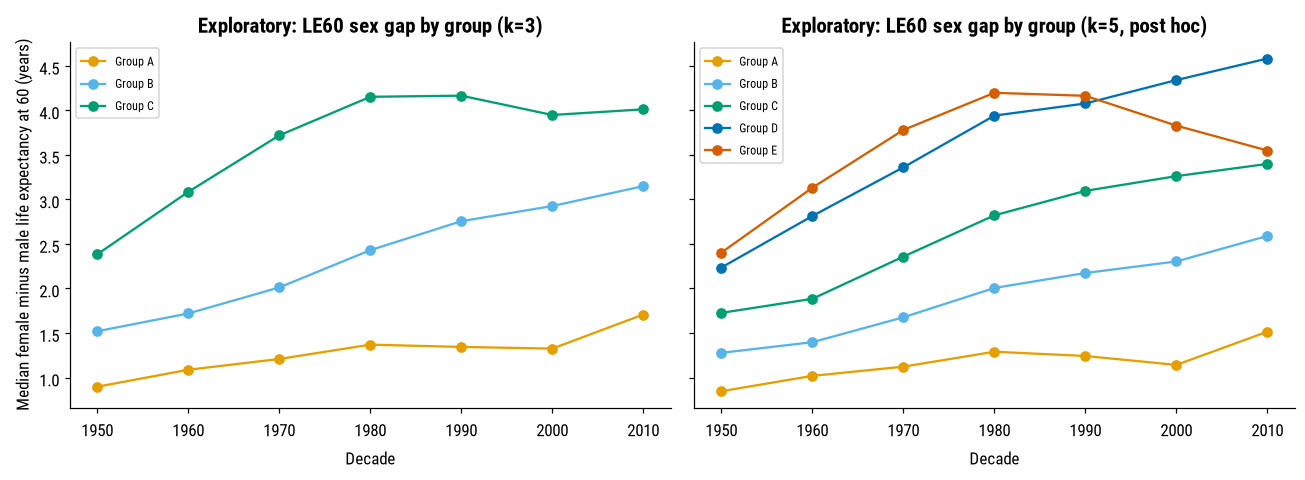

In [93]:
a = analysis[analysis['ISO3_code'].isin(X_primary.index) & (analysis['Time'] <= 2019)].copy()
a['decade'] = (a['Time'] // 10) * 10
a['gap'] = a['LE60Female'] - a['LE60Male']
a['k3'] = a['ISO3_code'].map(L3); a['k5'] = a['ISO3_code'].map(L5)
g3 = a.groupby(['decade', 'k3'])['gap'].median().unstack()
g5 = a.groupby(['decade', 'k5'])['gap'].median().unstack()
print(g3.round(2)); print(g5.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for axx, g, title in zip(ax, [g3, g5], ['Exploratory: LE60 sex gap by group (k=3)',
                                        'Exploratory: LE60 sex gap by group (k=5, post hoc)']):
    for col, c in zip(g.columns, OKABE):
        axx.plot(g.index, g[col], 'o-', color=c, label=f'Group {col}')
    axx.set_title(title); axx.set_xlabel('Decade'); axx.legend(fontsize=8)
ax[0].set_ylabel('Median female minus male life expectancy at 60 (years)')
plt.tight_layout(); plt.show()

## 5.14 E4: cluster variance share

**Method**: Share of variance explained by groups per decade

**Output**: Descriptive only, because the groups were built from the same indicators

In [51]:
def eta2(v, g):
    gm = v.mean(); ssb = sum(len(x) * (x.mean() - gm) ** 2 for _, x in v.groupby(g))
    return ssb / ((v - gm) ** 2).sum()

rows = []
for d in range(1950, 2020, 10):
    t = cd[(cd['decade'] == d) & cd['ISO3_code'].isin(X_primary.index)].set_index('ISO3_code')
    rows.append(dict(decade=d, **{f'{v}_k3': eta2(t[v], L3.reindex(t.index)) for v in IND},
                     **{f'{v}_k5': eta2(t[v], L5.reindex(t.index)) for v in IND}))
print(pd.DataFrame(rows).set_index('decade').round(2))

        TFR_k3  LEx_k3  LE60_k3  TFR_k5  LEx_k5  LE60_k5
decade                                                  
1950      0.65    0.76     0.55    0.76    0.82     0.64
1960      0.71    0.78     0.67    0.80    0.83     0.71
1970      0.75    0.79     0.70    0.82    0.83     0.75
1980      0.77    0.78     0.69    0.85    0.83     0.80
1990      0.78    0.80     0.67    0.83    0.85     0.83
2000      0.74    0.77     0.63    0.82    0.83     0.82
2010      0.68    0.74     0.64    0.78    0.81     0.80


## 5.15 Addendum entry 5

**Method**: Records fixed choices and limitations

**Output**: Logged

In [52]:
p = DATA_DIR.parent / 'analysis_plan_addendum.json'
add = json.loads(p.read_text(encoding='utf-8'))
add['entry_5'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': 'Exploratory aims E1, E3, E4 were declared before clustering. The D-vs-E focus at k=5 is post hoc.',
    'fixed_choices': ['Lag thresholds: LEx >= 60 and TFR < 3 using 5-year centered rolling medians; censoring reported, not imputed.',
                      'E3a: quadratic fit of LE60 on LEx per decade (primary set).',
                      'E4 cluster-variance shares are descriptive only (circular).'],
    'limitations': ['Lag results come from a selected subset (97 of 200).',
                    'Older-age and early-year values for low-data countries are partly model-based.'],
}
p.write_text(json.dumps(add, indent=2), encoding='utf-8'); print('entry_5 saved')

entry_5 saved


# 6 test H2 and show projection uncertainty

## 6.0 Pre-registers the H2 definitions

**Method**: Written and committed before running H2

**Output**: Addendum entry 6

In [53]:
p = DATA_DIR.parent / 'analysis_plan_addendum.json'
add = json.loads(p.read_text(encoding='utf-8'))
add['entry_6'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'note': ('Operational definitions for H2 fixed before the H2 code was run in this notebook. '
             'H2a was previewed once by the assistant on the Medium file (to test code) after the definitions were fixed; '
             'H2b was not previewed.'),
    'H2a': 'Primary set (n=200), Medium variant: SD and CV of TFR and of LEx are all smaller in 2100 than in 2019.',
    'H2b': ('Relative 95% PI width of 2100 population = (Upper 95 PI - Lower 95 PI) / Median PI. '
            'Supported iff Spearman rho(PC1 stage score, width) < 0 with p < 0.05 AND group medians A > B > C at k=3.'),
    'descriptive_extras': ['LE60 dispersion', 'group medians over time (fixed assignment)',
                           'High-minus-Low scenario spread (scenario, not probability)',
                           'population shares by group', 'fan charts'],
    'interpretation_rule': 'Convergence in projections partly reflects projection-model assumptions; reported as a property of the scenario.',
}
p.write_text(json.dumps(add, indent=2), encoding='utf-8'); print('entry_6 saved')

entry_6 saved


## 6.1 H2a: dispersion under Medium

**Method**: SD and CV of TFR and LEx in 2019, 2050 and 2100; group medians; population shares

**Output**: All four ratios below 1, so H2a is supported; LE60 spread grows by about 40%; group A holds about 19% of the 200-country population in 2019 and about 42% in 2100

In [54]:
P = analysis[analysis['ISO3_code'].isin(X_primary.index)]
rows = []
for v in ['TFR', 'LEx', 'LE60']:
    for y in [2019, 2050, 2100]:
        s = P.loc[P['Time'] == y, v]
        rows.append(dict(ind=v, year=y, mean=s.mean(), SD=s.std(), CV=s.std() / s.mean(), min=s.min(), max=s.max()))
disp = pd.DataFrame(rows); print(disp.round(3).to_string(index=False))

piv = disp.pivot(index='ind', columns='year', values=['SD', 'CV'])
ratio_sd = piv['SD'][2100] / piv['SD'][2019]; ratio_cv = piv['CV'][2100] / piv['CV'][2019]
print('\nSD ratio 2100/2019:', ratio_sd.round(3).to_dict()); print('CV ratio 2100/2019:', ratio_cv.round(3).to_dict())
print('H2a supported (as pre-specified):',
      all([ratio_sd['TFR'] < 1, ratio_cv['TFR'] < 1, ratio_sd['LEx'] < 1, ratio_cv['LEx'] < 1]))

g = P.assign(group=P['ISO3_code'].map(L3))
print(g[g['Time'].isin([2019, 2050, 2100])].groupby(['Time', 'group'])[['TFR', 'LEx', 'LE60']].median().unstack('group').round(2))
pop = g[g['Time'].isin([2019, 2100])].groupby(['Time', 'group'])['TPopulation1July'].sum().unstack('group')
print(pop.div(pop.sum(axis=1), axis=0).round(3))

 ind  year   mean    SD    CV    min    max
 TFR  2019  2.606 1.304 0.501  0.880  6.560
 TFR  2050  1.972 0.599 0.304  0.907  3.849
 TFR  2100  1.729 0.217 0.125  1.154  2.269
 LEx  2019 72.731 7.953 0.109 31.530 85.263
 LEx  2050 77.913 6.873 0.088 58.528 89.084
 LEx  2100 84.343 6.589 0.078 64.725 94.416
LE60  2019 20.049 3.271 0.163  9.762 27.367
LE60  2050 22.613 3.878 0.171 15.869 30.540
LE60  2100 26.946 4.571 0.170 17.020 35.183

SD ratio 2100/2019: {'LE60': 1.398, 'LEx': 0.829, 'TFR': 0.166}
CV ratio 2100/2019: {'LE60': 1.04, 'LEx': 0.714, 'TFR': 0.251}
H2a supported (as pre-specified): True
        TFR                LEx                 LE60              
group     A     B     C      A      B      C      A      B      C
Time                                                             
2019   4.26  2.21  1.54  63.15  73.67  81.10  16.63  19.84  23.79
2050   2.62  1.83  1.51  69.50  79.19  85.34  17.76  22.83  27.09
2100   1.95  1.72  1.56  77.06  85.96  90.93  21.62  27.72  31.

## 6.2 Loads OtherVariants

**Method**: Reads only needed columns in chunks, filtered to interval and scenario variants

**Output**: All 236 areas have interval rows for 2024–2100

In [55]:
ov_path = find_file('Demographic_Indicators_OtherVariants')
comp = 'gzip' if is_gzip(ov_path) else None
hdr = pd.read_csv(ov_path, compression=comp, encoding='utf-8-sig', nrows=0).columns.tolist()
need = ['ISO3_code', 'Variant', 'Time', 'TPopulation1July', 'TFR', 'LEx']
print(len(hdr), 'columns | missing needed:', [c for c in need if c not in hdr])

KEEP = ['Median PI', 'Lower 95 PI', 'Upper 95 PI', 'Lower 80 PI', 'Upper 80 PI', 'High', 'Low', 'Constant fertility']
parts = []
for ch in pd.read_csv(ov_path, compression=comp, encoding='utf-8-sig', usecols=need, chunksize=100_000):
    parts.append(ch[ch['ISO3_code'].isin(all_codes) & ch['Variant'].isin(KEEP) & ch['Time'].between(2024, 2100)])
ov = pd.concat(parts, ignore_index=True)
print(ov.shape); print(ov.groupby('Variant')['ISO3_code'].nunique())

pi_sets = [set(ov.loc[ov['Variant'] == v, 'ISO3_code']) for v in ['Median PI', 'Lower 95 PI', 'Upper 95 PI']]
pi_codes = set.intersection(*pi_sets)
missing_pi = sorted(set(all_codes) - pi_codes)
print('Countries without 95% PI rows:', len(missing_pi), [names[c] for c in missing_pi])
print('Primary countries with PI rows:', len(set(X_primary.index) & pi_codes), 'of', len(X_primary))
print('Years covered:', ov['Time'].min(), '-', ov['Time'].max())

'Demographic_Indicators_OtherVariants' -> ['WPP2024_Demographic_Indicators_OtherVariants_csv.gz']
67 columns | missing needed: []


C:\Users\ACER\AppData\Local\Temp\ipykernel_25300\3957713794.py:9: DtypeWarning: Columns (0: TPopulation1July) have mixed types. Specify dtype option on import or set low_memory=False.
  for ch in pd.read_csv(ov_path, compression=comp, encoding='utf-8-sig', usecols=need, chunksize=100_000):


(145376, 6)
Variant
Constant fertility    236
High                  236
Low                   236
Lower 80 PI           236
Lower 95 PI           236
Median PI             236
Upper 80 PI           236
Upper 95 PI           236
Name: ISO3_code, dtype: int64
Countries without 95% PI rows: 0 []
Primary countries with PI rows: 200 of 200
Years covered: 2024 - 2100


## 6.3 H2b and scenario spread

**Method**: Relative 95% interval width of 2100 population; Spearman $\rho$ against the stage score and a Kruskal–Wallis test; repeated for all 236 areas

**Output**: Primary: $\rho$ = −0.19, p = 0.007, medians A > B > C. All 236: $\rho$ = −0.07, p = 0.30, so the result is fragile

In [56]:
def wide_pi(year, col='TPopulation1July'):
    t = ov[(ov['Time'] == year) & ov['Variant'].isin(['Median PI', 'Lower 95 PI', 'Upper 95 PI'])]
    w = t.pivot(index='ISO3_code', columns='Variant', values=col)
    w['rel_width'] = (w['Upper 95 PI'] - w['Lower 95 PI']) / w['Median PI']
    return w

stage_all = pd.Series(to_scores(X_all)[:, 0], index=X_all.index)       # PC1 score for all 236 (small ones out of sample)
for label, codes in [('PRIMARY (n=200), pre-specified', X_primary.index), ('ALL (sensitivity)', X_all.index)]:
    w = wide_pi(2100); w = w.loc[w.index.intersection(codes)].copy()
    w['group'] = assign.loc[w.index, 'finer']; w['stage'] = stage_all.reindex(w.index)
    print(f'\n== {label}: n={len(w)} | ordering OK (lower<=median<=upper):',
          ((w['Lower 95 PI'] <= w['Median PI']) & (w['Median PI'] <= w['Upper 95 PI'])).mean().round(3))
    rho, pv = stats.spearmanr(w['stage'], w['rel_width'])
    med = w.groupby('group')['rel_width'].median()
    H, pk = stats.kruskal(*[x['rel_width'].values for _, x in w.groupby('group')])
    print(f'Spearman rho(stage, rel. width 2100) = {rho:.3f} (p={pv:.4f}) | KW H={H:.1f} p={pk:.4f}')
    print('Group medians:', med.round(3).to_dict())
    print('H2b supported (as pre-specified):', bool((rho < 0) and (pv < 0.05) and (med['A'] > med['B'] > med['C'])))

w50 = wide_pi(2050); w50 = w50.loc[w50.index.intersection(X_primary.index)]
print('\nDescriptive, 2050 median relative width by group:',
      w50.groupby(assign.loc[w50.index, 'finer'])['rel_width'].median().round(3).to_dict())

# scenario spread (High - Low) relative to Medium, 2100: a scenario range, NOT a probability interval
hl = ov[(ov['Time'] == 2100) & ov['Variant'].isin(['High', 'Low'])].pivot(index='ISO3_code', columns='Variant', values='TPopulation1July')
medpop = analysis[analysis['Time'] == 2100].set_index('ISO3_code')['TPopulation1July']
hl['scen_spread'] = (hl['High'] - hl['Low']) / medpop.reindex(hl.index)
hl = hl.loc[hl.index.intersection(X_primary.index)]
print('Scenario spread (High-Low)/Medium, 2100, median by group:',
      hl.groupby(assign.loc[hl.index, 'finer'])['scen_spread'].median().round(3).to_dict())


== PRIMARY (n=200), pre-specified: n=200 | ordering OK (lower<=median<=upper): 1.0


Spearman rho(stage, rel. width 2100) = -0.191 (p=0.0066) | KW H=7.9 p=0.0192
Group medians: {'A': 1.973, 'B': 1.762, 'C': 1.409}
H2b supported (as pre-specified): True

== ALL (sensitivity): n=236 | ordering OK (lower<=median<=upper): 1.0
Spearman rho(stage, rel. width 2100) = -0.067 (p=0.3028) | KW H=1.7 p=0.4312
Group medians: {'A': 2.018, 'B': 2.153, 'C': 1.777}
H2b supported (as pre-specified): False

Descriptive, 2050 median relative width by group: {'A': 0.532, 'B': 0.459, 'C': 0.361}
Scenario spread (High-Low)/Medium, 2100, median by group: {'A': 0.71, 'B': 0.795, 'C': 0.724}


## 6.4 Fan charts

**Method**: Median and 80/95% bands with estimates in black

**Output**: Nigeria’s range is much wider than Japan’s

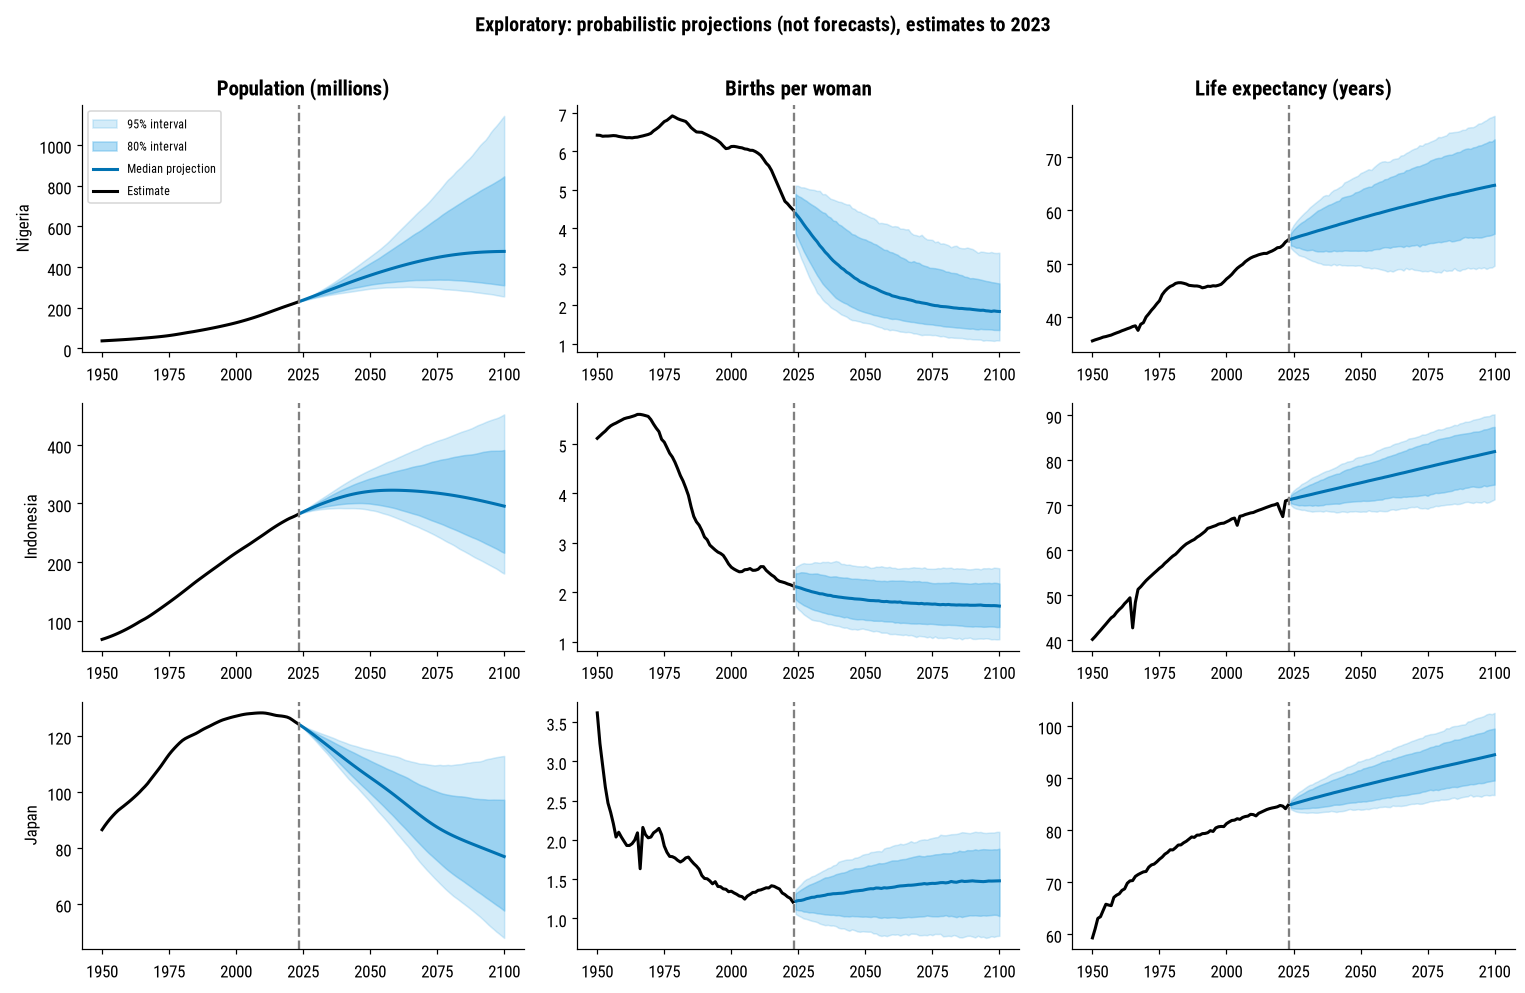

In [94]:
SEL = [('NGA', 'Nigeria'), ('IDN', 'Indonesia'), ('JPN', 'Japan')]
PLOT = [('TPopulation1July', 'Population (millions)', 1e-3), ('TFR', 'Births per woman', 1), ('LEx', 'Life expectancy (years)', 1)]
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for r, (iso, nm_) in enumerate(SEL):
    hist = analysis[(analysis['ISO3_code'] == iso) & (analysis['Time'] <= 2023)].set_index('Time')
    sub = ov[ov['ISO3_code'] == iso]
    for c, (col, lab, sc) in enumerate(PLOT):
        ax = axes[r, c]; f = sub.pivot(index='Time', columns='Variant', values=col) * sc
        ax.fill_between(f.index, f['Lower 95 PI'], f['Upper 95 PI'], color=OKABE[1], alpha=.25, label='95% interval')
        ax.fill_between(f.index, f['Lower 80 PI'], f['Upper 80 PI'], color=OKABE[1], alpha=.45, label='80% interval')
        ax.plot(f.index, f['Median PI'], color=OKABE[3], lw=2, label='Median projection')
        ax.plot(hist.index, hist[col] * sc, color='black', lw=2, label='Estimate')
        ax.axvline(2023.5, ls='--', c='gray')
        if r == 0: ax.set_title(lab)
        if c == 0: ax.set_ylabel(nm_)
axes[0, 0].legend(fontsize=8)
fig.suptitle('Exploratory: probabilistic projections (not forecasts), estimates to 2023', y=1.0)
plt.tight_layout(); plt.show()

## 6.5 Sensitivity grid

**Method**: 16 settings: end year × decade or 5-year medians × z-score or robust scaling × 200 or 236 countries; 100 bootstraps each

**Output**: k-means keeps 94–100% of countries in the same group; Ward and mixture models 71–93%; the rule picks k = 2 in all 16 settings

In [58]:
NB_GRID = 100      # fewer bootstraps than the main run (500); document this in the log

def feats(window, gran):
    a = analysis[analysis['Time'] <= window].copy()
    step = 10 if gran == 'decade' else 5
    a['p'] = (a['Time'] // step) * step
    cdx = a.groupby(['ISO3_code', 'p'])[IND].median().reset_index()
    w = cdx.pivot(index='ISO3_code', columns='p', values=IND)
    w.columns = [f'{i}_{d}' for i, d in w.columns]
    periods = sorted({int(c.split('_')[1]) for c in w.columns})
    return w[[f'{i}_{d}' for i in IND for d in periods]]

def match_pct(a, b):
    cont = np.zeros((a.max() + 1, b.max() + 1), int); np.add.at(cont, (a, b), 1)
    r, c = linear_sum_assignment(-cont); return cont[r, c].sum() / len(a)

prim = list(X_primary.index)
base = {k: pd.Series(base_labels[('kmeans', k)], index=prim) for k in [2, 3]}
out_rows, t0 = [], time.time()

for window, gran, scal, cset in itertools.product([2019, 2023], ['decade', '5y'], ['z', 'robust'], ['primary200', 'all236']):
    W = feats(window, gran); codes = prim if cset == 'primary200' else sorted(all_codes)
    X = W.loc[codes].values; mk = (lambda: StandardScaler()) if scal == 'z' else (lambda: RobustScaler())
    Z = mk().fit_transform(X)
    nc = int(np.searchsorted(np.cumsum(PCA().fit(Z).explained_variance_ratio_), 0.90) + 1)
    Sg = PCA(n_components=nc).fit_transform(Z); idx200 = [codes.index(c) for c in prim]
    rec = dict(window=window, gran=gran, scaling=scal, set=cset, n_features=W.shape[1], n_comp=nc)
    for k in [2, 3]:
        for algo in ALGOS:
            lab = fit_labels(Sg, algo, k)[idx200]; b = base[k].values
            rec[f'ARI_{algo}_k{k}'] = adjusted_rand_score(b, lab); rec[f'match_{algo}_k{k}'] = match_pct(b, lab)
    n = len(Sg); m = int(SUB * n); rng_g = np.random.default_rng(SEED)
    subs = [np.sort(rng_g.choice(n, m, replace=False)) for _ in range(NB_GRID)]
    emb = [PCA(n_components=nc).fit_transform(mk().fit_transform(X[i])) for i in subs]
    cr = []
    for algo in ALGOS:
        for k in K_RANGE:
            lab0 = fit_labels(Sg, algo, k)
            aris = [adjusted_rand_score(lab0[i], fit_labels(Sb, algo, k)) for i, Sb in zip(subs, emb)]
            cr.append(dict(algo=algo, k=k, min_share=np.bincount(lab0, minlength=k).min() / n,
                           sil=silhouette_score(Sg, lab0), medARI=np.median(aris)))
    cr = pd.DataFrame(cr); cr['elig'] = (cr['min_share'] >= .05) & (cr['sil'] >= .25)
    def choose(lo, hi):
        e = cr[cr['elig'] & cr['k'].between(lo, hi)]
        if e.empty: return (None, None, np.nan)
        t = e[e['medARI'] >= e['medARI'].max() - .02].copy(); t['o'] = t['algo'].map({'kmeans': 0, 'ward': 1, 'gmm': 2})
        r_ = t.sort_values(['k', 'o']).iloc[0]; return (r_['algo'], int(r_['k']), r_['medARI'])
    rec['primary_rule'] = choose(2, 10); rec['finer_rule'] = choose(3, 8)
    out_rows.append(rec); print(len(out_rows), window, gran, scal, cset, rec['primary_rule'][:2], rec['finer_rule'][:2], f'{time.time()-t0:.0f}s')

G = pd.DataFrame(out_rows); G.to_csv(out_dir / 'step6b_grid.csv', index=False)
for k in [2, 3]:
    for a in ALGOS:
        ari, mp = G[f'ARI_{a}_k{k}'], G[f'match_{a}_k{k}'] * 100
        print(f'k={k} {a:6s}: ARI vs baseline min/median/max = {ari.min():.2f}/{ari.median():.2f}/{ari.max():.2f}'
              f' | same group (%) = {mp.min():.1f}/{mp.median():.1f}/{mp.max():.1f}')
fmt = lambda t: f'{t[0]} k={t[1]}'
print(G['primary_rule'].map(fmt).value_counts().to_dict()); print(G['finer_rule'].map(fmt).value_counts().to_dict())

1 2019 decade z primary200 ('kmeans', 2) ('kmeans', 3) 151s
2 2019 decade z all236 ('kmeans', 2) ('kmeans', 3) 299s
3 2019 decade robust primary200 ('kmeans', 2) ('kmeans', 3) 443s
4 2019 decade robust all236 ('kmeans', 2) ('kmeans', 3) 585s
5 2019 5y z primary200 ('kmeans', 2) ('kmeans', 3) 734s
6 2019 5y z all236 ('kmeans', 2) ('kmeans', 4) 893s
7 2019 5y robust primary200 ('kmeans', 2) ('kmeans', 3) 1044s
8 2019 5y robust all236 ('kmeans', 2) ('kmeans', 3) 1196s
9 2023 decade z primary200 ('kmeans', 2) ('kmeans', 4) 1345s
10 2023 decade z all236 ('kmeans', 2) ('kmeans', 4) 1496s
11 2023 decade robust primary200 ('kmeans', 2) ('kmeans', 3) 1635s
12 2023 decade robust all236 ('kmeans', 2) ('kmeans', 3) 1794s
13 2023 5y z primary200 ('kmeans', 2) ('kmeans', 3) 1975s
14 2023 5y z all236 ('kmeans', 2) ('kmeans', 4) 2136s
15 2023 5y robust primary200 ('kmeans', 2) ('kmeans', 3) 2283s
16 2023 5y robust all236 ('kmeans', 2) ('kmeans', 3) 2419s
k=2 kmeans: ARI vs baseline min/median/max = 0.

## 6.6 Borderline countries

**Method**: Lists the lowest bootstrap keep shares

**Output**: 5 countries below 0.8: Solomon Islands (0.55), Bangladesh, Albania, Myanmar, Botswana

In [59]:
lab3, cent3 = relabel(base_labels[('kmeans', 3)], S)
kp = pd.Series(keep[('kmeans', 3)], index=X_primary.index)
dist = np.sqrt(((S[:, None, :] - cent3[None, :, :]) ** 2).sum(2)); srt = np.sort(dist, axis=1)
bd = pd.DataFrame({'country': names[X_primary.index].values, 'group': [letters(3)[i] for i in lab3],
                   'keep_share': kp.round(2).values, 'PC1': S[:, 0].round(2),
                   'margin': (srt[:, 1] - srt[:, 0]).round(2)}, index=X_primary.index)
print('Share keeping group in >=80% of resamples:', round((kp >= .8).mean(), 3), '| below 0.8:', int((kp < .8).sum()))
print(bd.sort_values('keep_share').head(14).to_string(index=False))
bd.to_csv(out_dir / 'step6_boundary_countries.csv')

Share keeping group in >=80% of resamples: 0.975 | below 0.8: 5
                         country group  keep_share   PC1  margin
                 Solomon Islands     B        0.55 -2.93    0.06
                      Bangladesh     B        0.63 -2.96    0.14
                         Albania     C        0.69  2.67    0.17
                         Myanmar     B        0.76 -2.55    0.32
                        Mongolia     B        0.80 -2.69    0.44
                        Botswana     A        0.80 -2.40    0.19
                         Grenada     B        0.81  2.24    0.19
                French Polynesia     B        0.82  2.62    0.23
                         Jamaica     C        0.85  2.12    0.32
          Bosnia and Herzegovina     B        0.87  2.35    0.24
                        Kiribati     B        0.88 -2.22    0.77
Bolivia (Plurinational State of)     B        0.89 -2.17    0.77
                           Egypt     B        0.89 -2.40    0.69
     Micronesia (Fed. Stat

## 6.7 Addendum entry 7

**Method**: Records results, including the fragile H2b

**Output**: Logged

In [60]:
p = DATA_DIR.parent / 'analysis_plan_addendum.json'
add = json.loads(p.read_text(encoding='utf-8'))
add['entry_7'] = {
    'written_on': dt.datetime.now().isoformat(timespec='seconds'),
    'H2a': 'Supported (SD and CV of TFR and LEx all lower in 2100 than in 2019); convergence is partly a projection-model property.',
    'H2b': 'Supported in the pre-specified primary set (rho=-0.19, p=0.007, medians A>B>C) but NOT in the all-236 sensitivity run (rho=-0.07, p=0.30); reported as fragile.',
    'H3': 'Supported (median bootstrap ARI 0.98 at k=3; 97.5% keep group in >=80% of resamples).',
    'grid_note': 'Sensitivity grid run with 100 bootstraps per setting; results in data/processed/step6b_grid.csv.',
    'limitations': ['Ward and GMM partitions agree less with k-means (boundaries are method-dependent).',
                    'Borderline countries are flagged and shown with lower confidence.'],
}
p.write_text(json.dumps(add, indent=2), encoding='utf-8'); print('entry_7 saved')

entry_7 saved


# 7

# 8 the ethics layer

## 8.1 Data card

- Source: UN DESA Population Division, World Population Prospects 2024 (Medium variant; OtherVariants for projection intervals); LE60 and births by sex from the supplement. License CC BY 3.0 IGO.
- Unit: country-year; 237 countries and areas in the file, 236 analysed (Holy See excluded: no supplement data, about 500 people). 200 primary (>= 100,000 people in 2023); 36 smaller areas assigned out of sample.
- Years: 1950-2023 estimates, 2024-2100 projections; 2101 dropped (supplement ends in 2100).
- Values are modelled UN estimates, not direct measurements; quality varies by country and period.
- Missing data: none in the analysis set after removing 2101, the Holy See, DoublingTime (undefined for shrinking populations), and free-text notes.
- Privacy: aggregated national indicators only; no individual-level records, so re-identification risk is negligible. Small populations have noisier modelled rates.
- Regions: UN geographic hierarchy; Northern America assigned manually to five locations whose parent ID was not in the file.
- Not used: income groups (not linked to countries in the file).

## 8.2 Limitations box

- Modelled estimates, especially for early years and low-data countries.
- Groups describe patterns along a continuum; 5 of 200 countries sit on a boundary.
- Group labels depend on the algorithm; k-means is stable, Ward and GMM agree less.
- Projections are scenarios with wide intervals, not forecasts; convergence is partly a model assumption.
- National averages hide differences within countries; no causal claims.
- The 2010s group profiles do not describe a country's future.

In [61]:
def r3(x):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), 3)

cr = crit.set_index(['algo', 'k'])
cols = ['silhouette', 'median_ARI', 'pct_keep80', 'min_share']
ledger = {
    'pc1_variance': r3(evr[0]), 'pc123_variance': r3(cum[2]),
    'kmeans_k2': {c: r3(cr.loc[('kmeans', 2), c]) for c in cols},
    'kmeans_k3': {c: r3(cr.loc[('kmeans', 3), c]) for c in cols},
    'ARI_vs_regions': {n: r3(adjusted_rand_score(L.values, meta.loc[L.index, 'Region'].values)) for n, L in LAB.items()},
    'dispersion_ratio_2100_vs_2019': {'SD': ratio_sd.round(3).to_dict(), 'CV': ratio_cv.round(3).to_dict()},
    'grid': {f'{a}_k{k}': {'ARI_min': r3(G[f'ARI_{a}_k{k}'].min()), 'ARI_median': r3(G[f'ARI_{a}_k{k}'].median()),
                           'same_group_min_pct': r3(G[f'match_{a}_k{k}'].min() * 100)} for k in [2, 3] for a in ALGOS},
    'borderline_below_0.8': int((kp < .8).sum()), 'share_keep_ge_0.8_k3': r3((kp >= .8).mean()),
    'lag': {'n_both_observed': int(len(ok)), 'median_years': r3(ok['lag'].median()),
            'p25': r3(ok['lag'].quantile(.25)), 'p75': r3(ok['lag'].quantile(.75))},
    'sex_gap_2010s_k5': g5.loc[2010].round(2).to_dict(),
    'n_countries': {'all': int(len(all_codes)), 'primary': int(len(X_primary))},
}
(DATA_DIR.parent / 'results_ledger.json').write_text(json.dumps(ledger, indent=2), encoding='utf-8')
print(json.dumps(ledger, indent=2))

{
  "pc1_variance": 0.786,
  "pc123_variance": 0.918,
  "kmeans_k2": {
    "silhouette": 0.517,
    "median_ARI": 1.0,
    "pct_keep80": 1.0,
    "min_share": 0.49
  },
  "kmeans_k3": {
    "silhouette": 0.431,
    "median_ARI": 0.979,
    "pct_keep80": 0.975,
    "min_share": 0.275
  },
  "ARI_vs_regions": {
    "primary": 0.225,
    "finer": 0.311,
    "k5_posthoc": 0.244
  },
  "dispersion_ratio_2100_vs_2019": {
    "SD": {
      "LE60": 1.398,
      "LEx": 0.829,
      "TFR": 0.166
    },
    "CV": {
      "LE60": 1.04,
      "LEx": 0.714,
      "TFR": 0.251
    }
  },
  "grid": {
    "kmeans_k2": {
      "ARI_min": 0.96,
      "ARI_median": 0.99,
      "same_group_min_pct": 99.0
    },
    "ward_k2": {
      "ARI_min": 0.257,
      "ARI_median": 0.617,
      "same_group_min_pct": 75.5
    },
    "gmm_k2": {
      "ARI_min": 0.3,
      "ARI_median": 0.647,
      "same_group_min_pct": 77.5
    },
    "kmeans_k3": {
      "ARI_min": 0.828,
      "ARI_median": 0.946,
      "same_group

# 9 visualization design

## 9.0 Figure setup

**Method**: Okabe–Ito colour-blind-safe palette, one colour per group on every figure

**Output**: Group descriptors (A: TFR 4.6, B: 2.4, C: 1.6)

In [95]:
FIG_DIR = DATA_DIR.parent / 'figures'; FIG_DIR.mkdir(exist_ok=True)
GC = {'A': '#E69F00', 'B': '#009E73', 'C': '#0072B2'}          # Okabe-Ito: colour = group, everywhere
K5C = {'D': '#CC79A7', 'E': '#D55E00'}
plt.rcParams.update({'font.size': 13, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 14})

prim = list(X_primary.index)
fa = pd.DataFrame({'k3': assign['finer'], 'k5': assign['k5_posthoc'], 'small_pop': assign['small_pop'],
                   'keep': pd.Series(keep[('kmeans', 3)], index=prim).reindex(assign.index)})
P = analysis[analysis['ISO3_code'].isin(prim)].copy(); P['g'] = P['ISO3_code'].map(fa['k3'])
d10 = P[(P['Time'] >= 2010) & (P['Time'] <= 2019)].groupby('ISO3_code')[['TFR', 'LEx']].median().join(fa['k3'])
prof = d10.groupby('k3')[['TFR', 'LEx']].median()
DESC = {g_: f"{g_}: TFR {prof.loc[g_, 'TFR']:.1f}, life expectancy {prof.loc[g_, 'LEx']:.0f} yrs" for g_ in 'ABC'}
print(prof.round(1))

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200); print('saved', FIG_DIR / name)

def header(fig, x, title, sub, source):
    fig.text(x, 0.965, title, fontsize=19, fontweight='bold', va='top')
    fig.text(x, 0.908, sub, fontsize=11, color='#444', va='top')
    fig.text(x, 0.012, source, fontsize=9, color='#555')

    TFR   LEx
k3           
A   4.6  62.1
B   2.4  72.9
C   1.6  80.5


## 9.1 Map of pathways

**Method**: Natural Earth boundaries drawn directly; hatching marks borderline or out-of-sample countries

**Output**: fig1_map.png

saved ..\figures\fig1_map.png


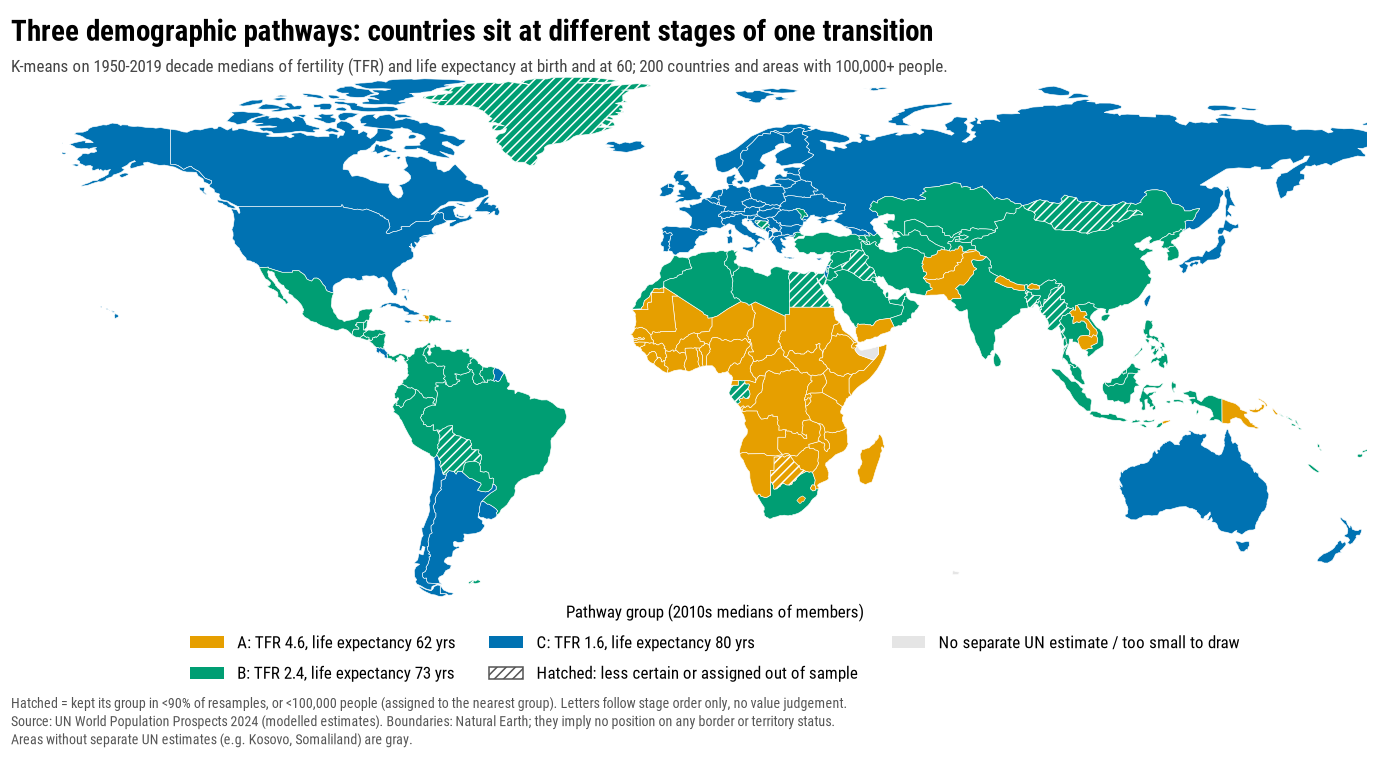

In [96]:
geo_path = FIG_DIR / 'ne_110m_admin_0_countries.geojson'
if not geo_path.exists():
    urllib.request.urlretrieve('https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson', geo_path)
geo = json.loads(geo_path.read_text(encoding='utf-8'))

def rings(geom):
    return [geom['coordinates']] if geom['type'] == 'Polygon' else geom['coordinates']

feats = [f for f in geo['features'] if f['properties']['ADMIN'] != 'Antarctica']
feats.sort(key=lambda f: -sum(len(r[0]) for r in rings(f['geometry'])))      # big shapes first, enclaves on top

def fig_map():
    fig, ax = plt.subplots(figsize=(13.33, 7.0))
    for f in feats:
        p = f['properties']; c = p['ISO_A3_EH'] if p['ISO_A3_EH'] not in ('-99', None) else p['ADM0_A3']
        if c in fa.index and pd.notna(fa.loc[c, 'k3']):
            uncertain = bool(fa.loc[c, 'small_pop']) or (fa.loc[c, 'keep'] < 0.9)
            kw = dict(facecolor=GC[fa.loc[c, 'k3']], edgecolor='white', lw=.4, hatch='////' if uncertain else None)
        else:
            kw = dict(facecolor='#E5E5E5', edgecolor='white', lw=.4)
        for poly in rings(f['geometry']):
            ax.add_patch(MplPolygon(np.array(poly[0]), closed=True, **kw))
    ax.set_xlim(-170, 180); ax.set_ylim(-75, 84); ax.set_aspect('equal'); ax.axis('off')
    h = [Patch(facecolor=GC[x], label=DESC[x]) for x in 'ABC'] + \
        [Patch(facecolor='white', edgecolor='#555', hatch='////', label='Hatched: less certain or assigned out of sample'),
         Patch(facecolor='#E5E5E5', label='No separate UN estimate / too small to draw')]
    ax.legend(handles=h, loc='lower center', ncol=3, frameon=False, fontsize=11, bbox_to_anchor=(0.5, -0.05),
              title='Pathway group (2010s medians of members)', title_fontsize=11)
    header(fig, 0.02, 'Three demographic pathways: countries sit at different stages of one transition',
           'K-means on 1950-2019 decade medians of fertility (TFR) and life expectancy at birth and at 60; 200 countries and areas with 100,000+ people.',
           'Hatched = kept its group in <90% of resamples, or <100,000 people (assigned to the nearest group). Letters follow stage order only, no value judgement.\n'
           'Source: UN World Population Prospects 2024 (modelled estimates). Boundaries: Natural Earth; they imply no position on any border or territory status.\n'
           'Areas without separate UN estimates (e.g. Kosovo, Somaliland) are gray.')
    fig.subplots_adjust(left=.01, right=.99, top=.88, bottom=.11); save(fig, 'fig1_map.png'); plt.show()

fig_map()

## 9.2 Corridor and trajectories

**Method**: Thin country paths, thick group medians, estimates solid and projections dashed

**Output**: fig2_corridor.png

saved ..\figures\fig2_corridor.png


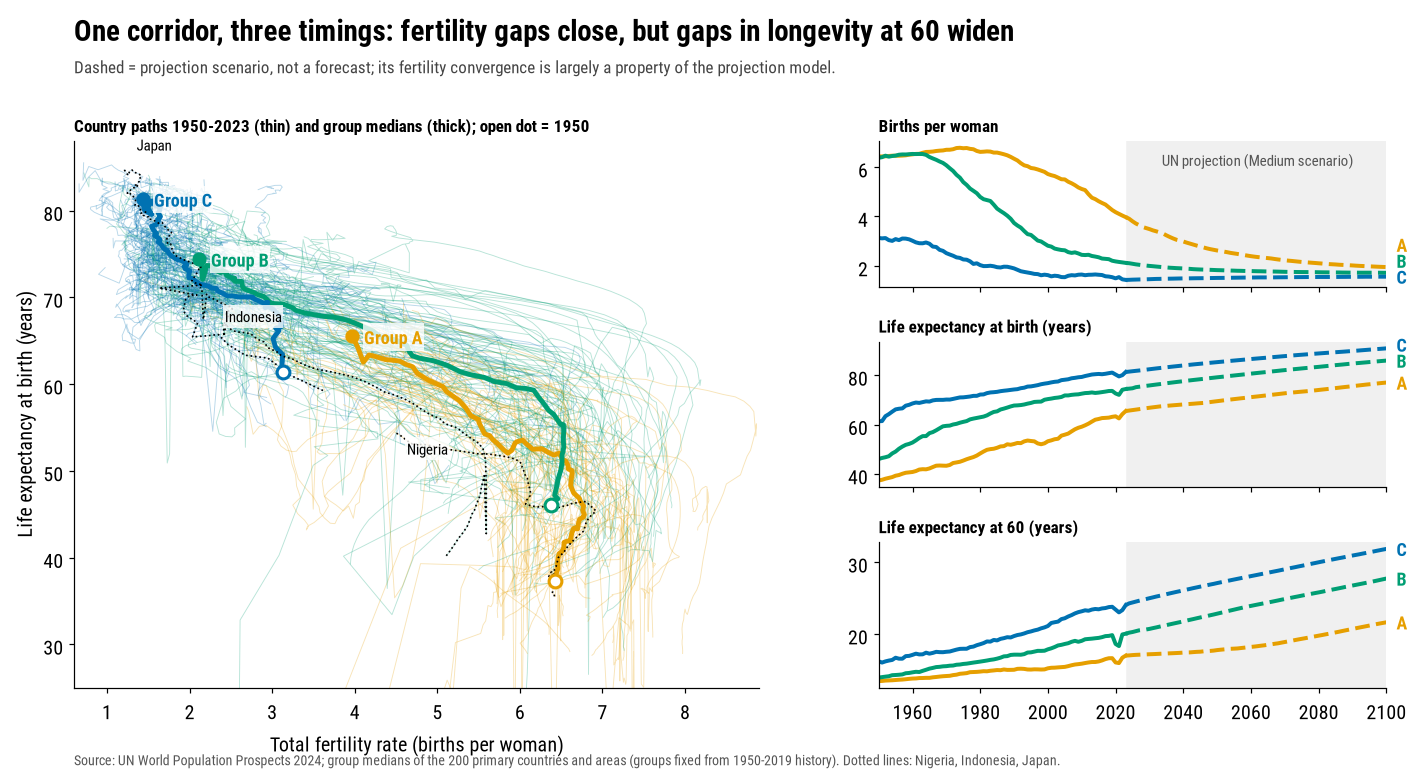

In [97]:
def fig_corridor():
    fig = plt.figure(figsize=(13.33, 7.2))
    gs = GridSpec(3, 2, width_ratios=[1.35, 1], hspace=.38, wspace=.2, left=.065, right=.96, top=.80, bottom=.11)
    ax = fig.add_subplot(gs[:, 0]); e23 = P[P['Time'] <= 2023].sort_values(['ISO3_code', 'Time'])
    for iso, gg in e23.groupby('ISO3_code'):
        ax.plot(gg['TFR'], gg['LEx'], color=GC[gg['g'].iloc[0]], lw=.6, alpha=.28)
    med = e23.groupby(['g', 'Time'])[['TFR', 'LEx']].median().reset_index()
    for grp in 'ABC':
        m = med[med['g'] == grp]; ax.plot(m['TFR'], m['LEx'], color=GC[grp], lw=3.2)
        ax.scatter(m['TFR'].iloc[0], m['LEx'].iloc[0], s=70, facecolor='white', edgecolor=GC[grp], lw=2, zorder=5)
        ax.scatter(m['TFR'].iloc[-1], m['LEx'].iloc[-1], s=70, color=GC[grp], zorder=5)
        ax.text(m['TFR'].iloc[-1] + .14, m['LEx'].iloc[-1] - .9, f'Group {grp}', color=GC[grp], fontsize=12, fontweight='bold',
                bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=1))
    for iso, nm_, (dx, dy) in [('NGA', 'Nigeria', (.15, -2.6)), ('IDN', 'Indonesia', (.3, -4.0)), ('JPN', 'Japan', (.15, 2.2))]:
        gg = e23[e23['ISO3_code'] == iso]; ax.plot(gg['TFR'], gg['LEx'], color='black', lw=1.1, ls=':')
        ax.text(gg['TFR'].iloc[-1] + dx, gg['LEx'].iloc[-1] + dy, nm_, fontsize=10, bbox=dict(facecolor='white', edgecolor='none', alpha=.8, pad=1))
    ax.set_xlim(.6, 8.9); ax.set_ylim(25, 88)
    ax.set_xlabel('Total fertility rate (births per woman)'); ax.set_ylabel('Life expectancy at birth (years)')
    ax.set_title('Country paths 1950-2023 (thin) and group medians (thick); open dot = 1950', loc='left', fontsize=11)
    gm = P.groupby(['g', 'Time'])[['TFR', 'LEx', 'LE60']].median().reset_index()
    for i, (col, lab) in enumerate([('TFR', 'Births per woman'), ('LEx', 'Life expectancy at birth (years)'), ('LE60', 'Life expectancy at 60 (years)')]):
        a = fig.add_subplot(gs[i, 1]); a.axvspan(2023.5, 2100, color='#F0F0F0', zorder=0)
        for grp in 'ABC':
            m = gm[gm['g'] == grp]
            a.plot(m.loc[m['Time'] <= 2023, 'Time'], m.loc[m['Time'] <= 2023, col], color=GC[grp], lw=2.6)
            a.plot(m.loc[m['Time'] >= 2023, 'Time'], m.loc[m['Time'] >= 2023, col], color=GC[grp], lw=2.6, ls='--')
        a.set_title(lab, loc='left', fontsize=11); a.set_xlim(1950, 2100)
        ends = {grp: gm[(gm['g'] == grp) & (gm['Time'] == 2100)][col].iloc[0] for grp in 'ABC'}
        lo_, hi_ = a.get_ylim(); gap_ = .11 * (hi_ - lo_); pos = dict(ends); order = sorted(pos, key=pos.get)
        for k_ in range(1, 3):
            if pos[order[k_]] - pos[order[k_ - 1]] < gap_: pos[order[k_]] = pos[order[k_ - 1]] + gap_
        for grp in 'ABC': a.text(2103, pos[grp], grp, color=GC[grp], fontsize=12, fontweight='bold', va='center', clip_on=False)
        if i == 0: a.text(2062, a.get_ylim()[1] * .95, 'UN projection (Medium scenario)', fontsize=10, color='#555', ha='center', va='top')
        if i < 2: a.set_xticklabels([])
    header(fig, .065, 'One corridor, three timings: fertility gaps close, but gaps in longevity at 60 widen',
           'Dashed = projection scenario, not a forecast; its fertility convergence is largely a property of the projection model.',
           'Source: UN World Population Prospects 2024; group medians of the 200 primary countries and areas (groups fixed from 1950-2019 history). Dotted lines: Nigeria, Indonesia, Japan.')
    save(fig, 'fig2_corridor.png'); plt.show()

fig_corridor()

## 9.3 Robustness

**Method**: Bootstrap keep-share strip and a 16-setting agreement heatmap

**Output**: fig3a_robustness.png

saved ..\figures\fig3a_robustness.png


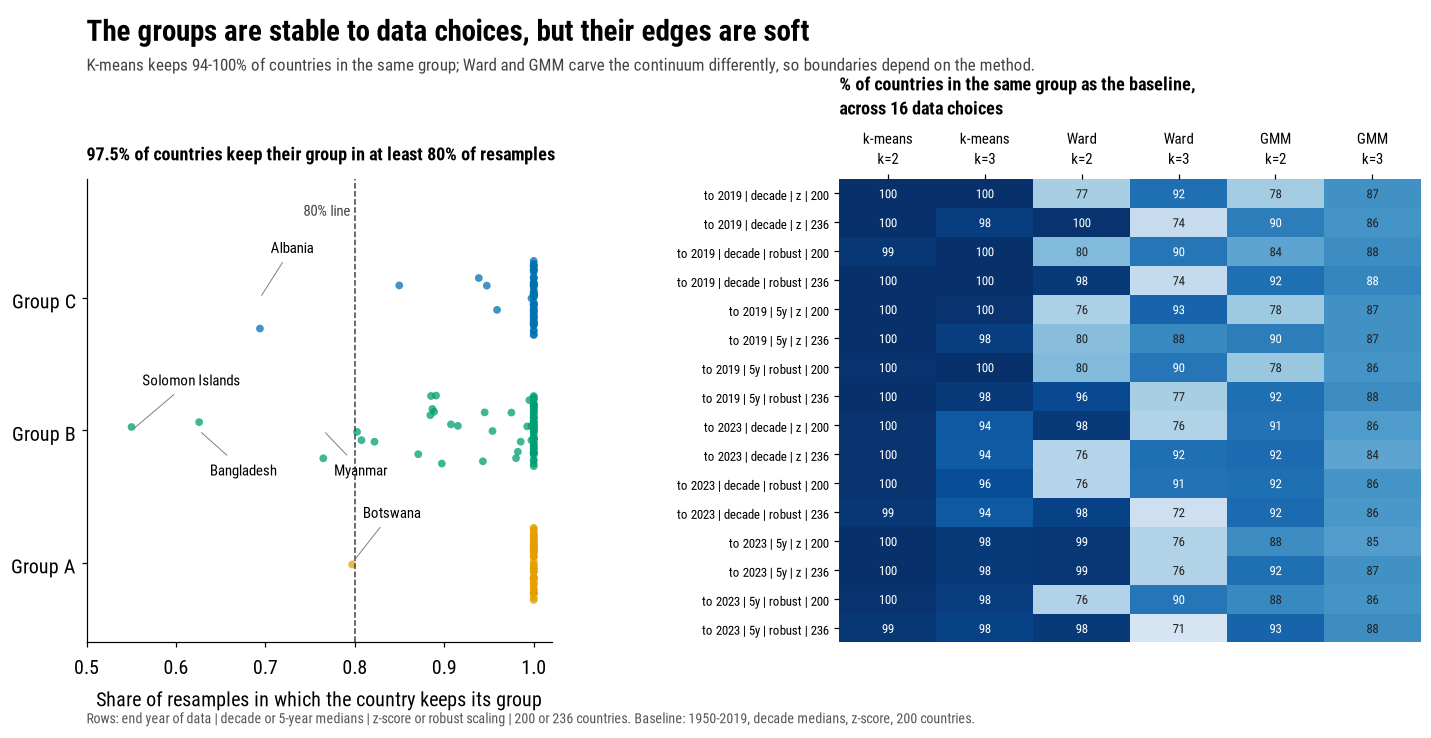

In [98]:
def fig_robust():
    fig = plt.figure(figsize=(13.33, 6.8)); gs = GridSpec(1, 2, width_ratios=[1, 1.25], wspace=.55, left=.075, right=.985, top=.74, bottom=.12)
    ax = fig.add_subplot(gs[0]); rng_f = np.random.default_rng(3); pr = fa.loc[prim]
    for i, grp in enumerate('ABC'):
        s = pr[pr['k3'] == grp]['keep']
        ax.scatter(s, np.full(len(s), i) + rng_f.uniform(-.28, .28, len(s)), s=26, color=GC[grp], alpha=.75, edgecolor='none')
    ax.axvline(.8, ls='--', color='#444', lw=1); ax.text(.795, 2.62, '80% line', ha='right', fontsize=10, color='#444')
    low = pr[pr['keep'] < .8].sort_values('keep')
    for (iso, r_), o in zip(low.iterrows(), [.34, -.34, .34, -.34, .34, -.34, .34, -.34]):
        yi = 'ABC'.index(r_['k3'])
        ax.annotate(meta.loc[iso, 'Location'], (r_['keep'], yi), xytext=(r_['keep'] + .012, yi + o), fontsize=9.5,
                    arrowprops=dict(arrowstyle='-', color='#777', lw=.6))
    ax.set_yticks(range(3)); ax.set_yticklabels([f'Group {x}' for x in 'ABC']); ax.set_xlim(.5, 1.02); ax.set_ylim(-.6, 2.9)
    ax.set_xlabel('Share of resamples in which the country keeps its group')
    ax.set_title(f"{(pr['keep'] >= .8).mean() * 100:.1f}% of countries keep their group in at least 80% of resamples", loc='left', fontsize=12, pad=12)
    ax2 = fig.add_subplot(gs[1]); cols = [('kmeans', 2), ('kmeans', 3), ('ward', 2), ('ward', 3), ('gmm', 2), ('gmm', 3)]
    M = np.array([[G.loc[i, f'match_{a}_k{k}'] * 100 for a, k in cols] for i in range(len(G))])
    ax2.imshow(M, cmap='Blues', vmin=65, vmax=100, aspect='auto')
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax2.text(j, i, f'{M[i, j]:.0f}', ha='center', va='center', fontsize=8.5, color='white' if M[i, j] > 88 else '#222')
    nm_ = {'kmeans': 'k-means', 'ward': 'Ward', 'gmm': 'GMM'}
    ax2.set_xticks(range(6)); ax2.set_xticklabels([f'{nm_[a]}\nk={k}' for a, k in cols], fontsize=10)
    ax2.set_yticks(range(len(G)))
    ax2.set_yticklabels([f"to {r_.window} | {r_.gran} | {'z' if r_.scaling == 'z' else 'robust'} | {'200' if r_.set == 'primary200' else '236'}" for r_ in G.itertuples()], fontsize=8.5)
    ax2.xaxis.tick_top(); [s_.set_visible(False) for s_ in ax2.spines.values()]
    ax2.set_title('% of countries in the same group as the baseline,\nacross 16 data choices', loc='left', fontsize=12, pad=42)
    header(fig, .075, 'The groups are stable to data choices, but their edges are soft',
           'K-means keeps 94-100% of countries in the same group; Ward and GMM carve the continuum differently, so boundaries depend on the method.',
           'Rows: end year of data | decade or 5-year medians | z-score or robust scaling | 200 or 236 countries. Baseline: 1950-2019, decade medians, z-score, 200 countries.')
    save(fig, 'fig3a_robustness.png'); plt.show()

fig_robust()

## 9.4 Figure 4, what presists

**Method**: Spread of LEx vs LE60, and the sex-gap divergence

**Output**: fig4_persist.png

saved ..\figures\fig4_persist.png


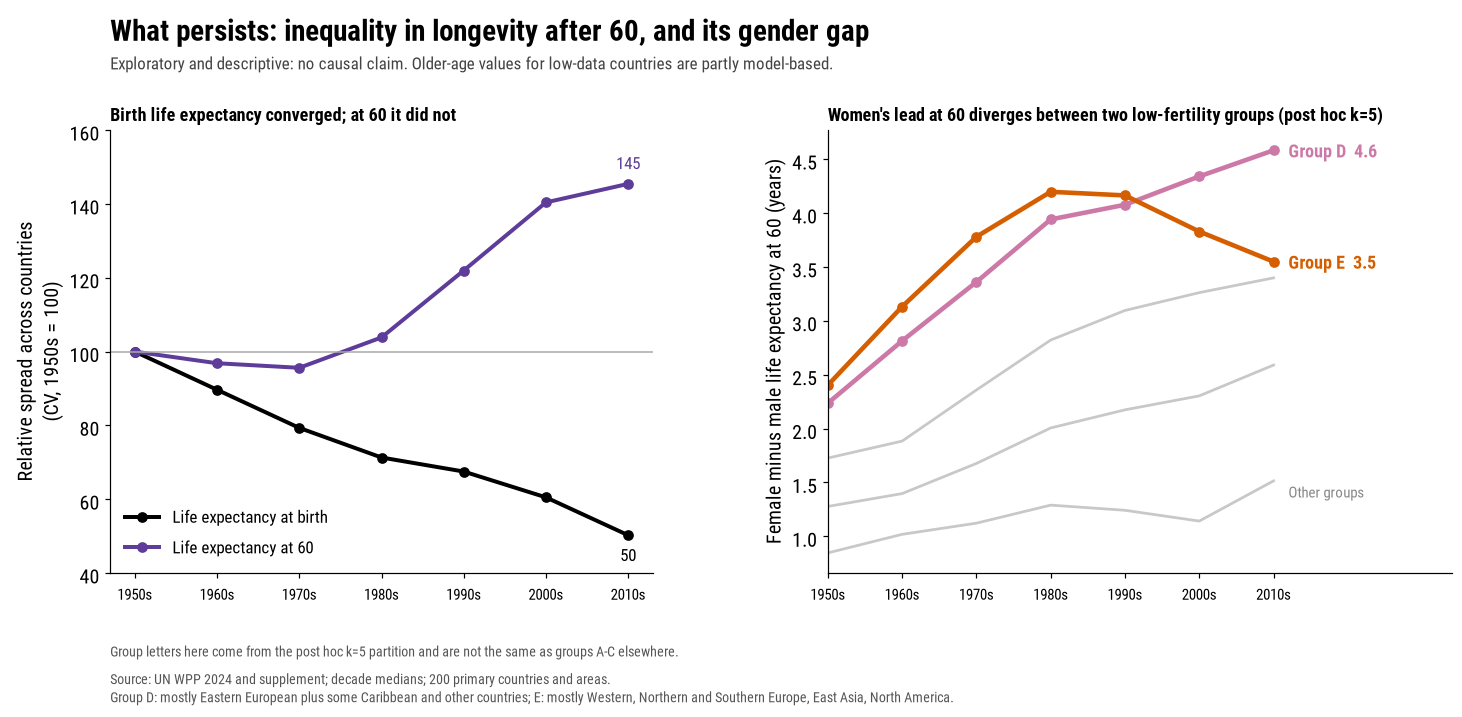

In [99]:
def fig_persist():
    fig, axs = plt.subplots(1, 2, figsize=(13.33, 6.6), gridspec_kw=dict(width_ratios=[1, 1.15], wspace=.3, left=.07, right=.985, top=.80, bottom=.19))
    cdm = analysis[(analysis['Time'] <= 2019) & analysis['ISO3_code'].isin(prim)].copy(); cdm['decade'] = (cdm['Time'] // 10) * 10
    dd = cdm.groupby(['ISO3_code', 'decade'])[['LEx', 'LE60']].median().reset_index()
    cv_ = dd.groupby('decade')[['LEx', 'LE60']].agg(lambda s: s.std() / s.mean()); idx = cv_ / cv_.iloc[0] * 100
    a = axs[0]
    a.plot(idx.index, idx['LEx'], 'o-', color='black', lw=2.6, label='Life expectancy at birth')
    a.plot(idx.index, idx['LE60'], 'o-', color='#5E3C99', lw=2.6, label='Life expectancy at 60')
    a.axhline(100, color='#AAA', lw=1); a.set_ylabel('Relative spread across countries\n(CV, 1950s = 100)')
    a.set_xticks(idx.index); a.set_xticklabels([f'{x}s' for x in idx.index], fontsize=10); a.set_ylim(40, 160)
    a.text(2010, idx['LEx'].iloc[-1] - 7, f"{idx['LEx'].iloc[-1]:.0f}", ha='center', fontsize=11)
    a.text(2010, idx['LE60'].iloc[-1] + 4, f"{idx['LE60'].iloc[-1]:.0f}", ha='center', fontsize=11, color='#5E3C99')
    a.legend(frameon=False, loc='lower left', fontsize=11); a.set_title('Birth life expectancy converged; at 60 it did not', loc='left', fontsize=12)
    b = axs[1]
    sg = cdm.assign(k5=cdm['ISO3_code'].map(fa['k5']), gap=cdm['LE60Female'] - cdm['LE60Male']).groupby(['decade', 'k5'])['gap'].median().unstack()
    for grp in 'ABC': b.plot(sg.index, sg[grp], color='#C8C8C8', lw=1.8)
    for grp, c in K5C.items():
        b.plot(sg.index, sg[grp], 'o-', color=c, lw=3, ms=6)
        b.text(2012, sg[grp].iloc[-1], f"Group {grp}  {sg[grp].iloc[-1]:.1f}", color=c, fontsize=12, fontweight='bold', va='center')
    b.text(2012, sg['A'].iloc[-1] - .1, 'Other groups', color='#888', fontsize=10, va='center')
    b.set_xlim(1950, 2034); b.set_xticks(sg.index); b.set_xticklabels([f'{x}s' for x in sg.index], fontsize=10)
    b.set_ylabel('Female minus male life expectancy at 60 (years)')
    b.set_title("Women's lead at 60 diverges between two low-fertility groups (post hoc k=5)", loc='left', fontsize=12)
    header(fig, .07, 'What persists: inequality in longevity after 60, and its gender gap',
           'Exploratory and descriptive: no causal claim. Older-age values for low-data countries are partly model-based.',
           'Source: UN WPP 2024 and supplement; decade medians; 200 primary countries and areas.\nGroup D: mostly Eastern European plus some Caribbean and other countries; '
           'E: mostly Western, Northern and Southern Europe, East Asia, North America.')
    fig.text(.07, .075, 'Group letters here come from the post hoc k=5 partition and are not the same as groups A-C elsewhere.', fontsize=9, color='#555')
    save(fig, 'fig4_persist.png'); plt.show()

fig_persist()

## 9.5 Projection uncertainty

**Method**: Fan charts in each country’s group colour

**Output**: fig3b_uncertainty.png

saved ..\figures\fig3b_uncertainty.png


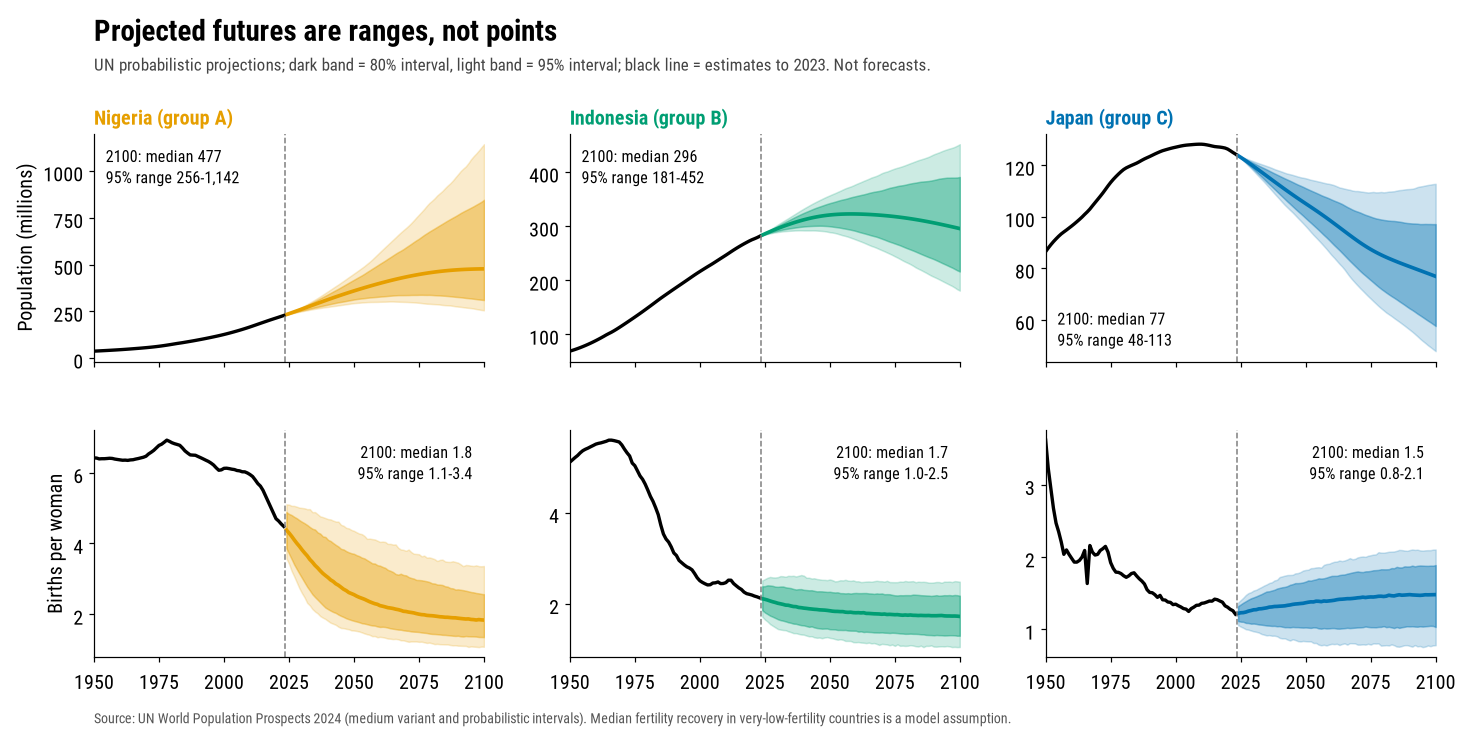

In [100]:
def fig_fan():
    SEL = [('NGA', 'Nigeria'), ('IDN', 'Indonesia'), ('JPN', 'Japan')]
    ROWS = [('TPopulation1July', 'Population (millions)', 1e-3), ('TFR', 'Births per woman', 1)]
    fig, axes = plt.subplots(2, 3, figsize=(13.33, 6.8), gridspec_kw=dict(left=.07, right=.985, top=.80, bottom=.1, hspace=.3, wspace=.22))
    for c, (iso, nm_) in enumerate(SEL):
        col_ = GC[fa.loc[iso, 'k3']]; hist = analysis[(analysis['ISO3_code'] == iso) & (analysis['Time'] <= 2023)].set_index('Time')
        sub = ov[ov['ISO3_code'] == iso]
        for r, (var, lab, sc_) in enumerate(ROWS):
            ax = axes[r, c]; f = sub.pivot(index='Time', columns='Variant', values=var) * sc_
            ax.fill_between(f.index, f['Lower 95 PI'], f['Upper 95 PI'], color=col_, alpha=.20)
            ax.fill_between(f.index, f['Lower 80 PI'], f['Upper 80 PI'], color=col_, alpha=.40)
            ax.plot(f.index, f['Median PI'], color=col_, lw=2.4); ax.plot(hist.index, hist[var] * sc_, color='black', lw=2.2)
            ax.axvline(2023.5, ls='--', c='gray', lw=1); ax.set_xlim(1950, 2100)
            lo, md, hi = f.loc[2100, 'Lower 95 PI'], f.loc[2100, 'Median PI'], f.loc[2100, 'Upper 95 PI']
            fmt_ = (lambda v: f'{v:,.0f}') if r == 0 else (lambda v: f'{v:.1f}')
            if r == 1: px, py, ha_, va_ = .97, .95, 'right', 'top'
            elif iso == 'JPN': px, py, ha_, va_ = .03, .05, 'left', 'bottom'
            else: px, py, ha_, va_ = .03, .95, 'left', 'top'
            ax.text(px, py, f'2100: median {fmt_(md)}\n95% range {fmt_(lo)}-{fmt_(hi)}', transform=ax.transAxes, ha=ha_, va=va_, fontsize=10.5,
                    bbox=dict(facecolor='white', edgecolor='none', alpha=.85, pad=2))
            if r == 0: ax.set_title(f"{nm_} (group {fa.loc[iso, 'k3']})", loc='left', fontsize=13, color=col_)
            if c == 0: ax.set_ylabel(lab)
            if r == 0: ax.set_xticklabels([])
    header(fig, .07, 'Projected futures are ranges, not points',
           'UN probabilistic projections; dark band = 80% interval, light band = 95% interval; black line = estimates to 2023. Not forecasts.',
           'Source: UN World Population Prospects 2024 (medium variant and probabilistic intervals). Median fertility recovery in very-low-fertility countries is a model assumption.')
    save(fig, 'fig3b_uncertainty.png'); plt.show()

fig_fan()